<a href="https://colab.research.google.com/github/Esther3377/Esther3377/blob/main/CodeAlpha_LOAD_DEFAULT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

df = pd.read_excel(
    "/content/sample_data/Loan_default perfect.xlsx"
)

print(df.head())

       LoanID  Age  Income  LoanAmount  CreditScore  MonthsEmployed  \
0  I38PQUQS96   56   85994       50587          520              80   
1  HPSK72WA7R   69   50432      124440          458              15   
2  C1OZ6DPJ8Y   46   84208      129188          451              26   
3  V2KKSFM3UN   32   31713       44799          743               0   
4  EY08JDHTZP   60   20437        9139          633               8   

   NumCreditLines  InterestRate  LoanTerm  DTIRatio    Education  \
0               4         15.23        36      0.44   Bachelor's   
1               1          4.81        60      0.68     Master's   
2               3         21.17        24      0.31     Master's   
3               3          7.07        24      0.23  High School   
4               4          6.51        48      0.73   Bachelor's   

  EmploymentType MaritalStatus HasMortgage HasDependents LoanPurpose  \
0      Full-time      Divorced         Yes           Yes       Other   
1      Full-time    

In [ ]:
print("Dataset size:", df.shape)

Dataset size: (255347, 18)


In [ ]:
print(df.columns.tolist())

['LoanID', 'Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed', 'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio', 'Education', 'EmploymentType', 'MaritalStatus', 'HasMortgage', 'HasDependents', 'LoanPurpose', 'HasCoSigner', 'Default']


In [ ]:
print(df["Default"].value_counts())

Default
0    225694
1     29653
Name: count, dtype: int64


In [ ]:
print(df["Default"].value_counts(normalize=True) * 100)

Default
0    88.387175
1    11.612825
Name: proportion, dtype: float64


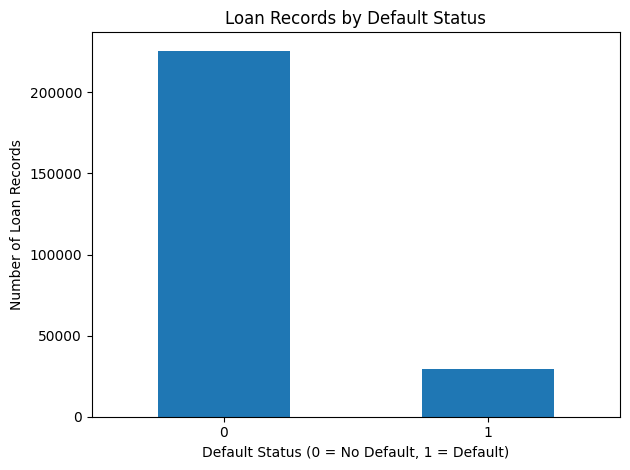

In [ ]:
import matplotlib.pyplot as plt

default_counts = df["Default"].value_counts().sort_index()

default_counts.plot(kind="bar")

plt.title("Loan Records by Default Status")
plt.xlabel("Default Status (0 = No Default, 1 = Default)")
plt.ylabel("Number of Loan Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
employment_default = df.groupby("EmploymentType")["Default"].mean() * 100

print(employment_default.sort_values(ascending=False))

EmploymentType
Unemployed       13.552895
Part-time        11.965213
Self-employed    11.462029
Full-time         9.463366
Name: Default, dtype: float64


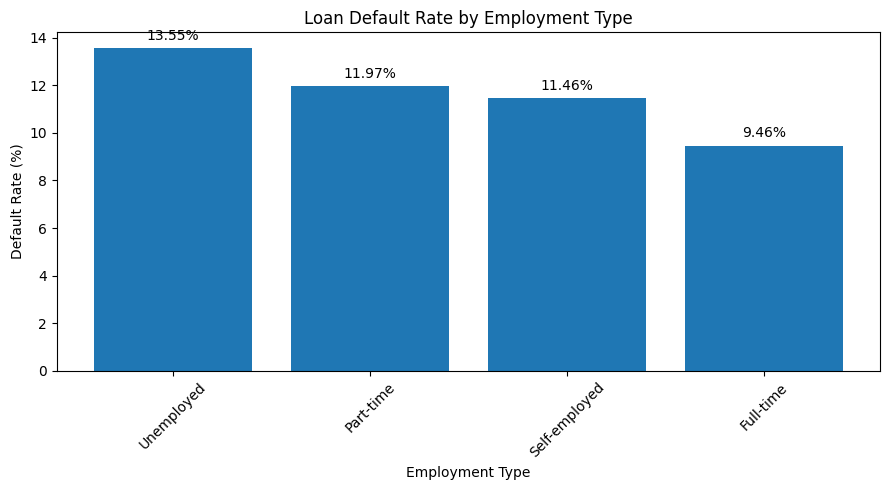

In [ ]:


import matplotlib.pyplot as plt

employment_default = (
    df.groupby("EmploymentType")["Default"].mean() * 100
).sort_values(ascending=False)

plt.figure(figsize=(9, 5))

bars = plt.bar(
    employment_default.index.astype(str),
    employment_default.values
)

# Add the actual values above each bar
for bar in bars:
    value = bar.get_height()
    plt.annotate(
        f"{value:.2f}%",
        (bar.get_x() + bar.get_width() / 2, value),
        ha="center",
        va="bottom",
        xytext=(0, 4),
        textcoords="offset points"
    )

plt.title("Loan Default Rate by Employment Type")
plt.xlabel("Employment Type")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

df["CreditScoreGroup"] = pd.cut(
    df["CreditScore"],
    bins=[0, 500, 600, 650, 700, 850],
    labels=[
        "Below 500",
        "500–599",
        "600–649",
        "650–699",
        "700–850"
    ],
    right=False
)

print(df["CreditScoreGroup"].value_counts().sort_index())

CreditScoreGroup
Below 500    93029
500–599      46454
600–649      23283
650–699      23151
700–850      69430
Name: count, dtype: int64


In [ ]:
credit_default = (
    df.groupby("CreditScoreGroup", observed=False)["Default"]
      .mean() * 100
)

print(credit_default.round(2))

CreditScoreGroup
Below 500    12.77
500–599      11.83
600–649      11.20
650–699      11.16
700–850      10.21
Name: Default, dtype: float64


In [ ]:

import pandas as pd
from google.colab import files

uploaded = files.upload()

df = pd.read_excel(next(iter(uploaded)))

print(df.head())

In [ ]:
df["DTIRatio"].describe()

,DTIRatio
count,255347.000000
mean,0.500212
std,0.230917
min,0.100000
25%,0.300000
50%,0.500000
75%,0.700000
max,0.900000


In [ ]:

# Group borrowers by their DTI ratio
df["DTI_Group"] = pd.cut(
    df["DTIRatio"],
    bins=[0, 0.2, 0.4, 0.6, 0.8, 1.0],
    labels=["0.0–0.2", "0.2–0.4", "0.4–0.6", "0.6–0.8", "0.8–1.0"],
    include_lowest=True
)

# Calculate the default rate in each group
dti_default_rate = df.groupby(
    "DTI_Group", observed=False
)["Default"].mean() * 100

print(dti_default_rate.round(2))

DTI_Group
0.0–0.2    10.36
0.2–0.4    11.16
0.4–0.6    11.82
0.6–0.8    12.24
0.8–1.0    12.18
Name: Default, dtype: float64


In [ ]:

# Group borrowers by their DTI ratio
df["DTI_Group"] = pd.cut(
    df["DTIRatio"],
    bins=[0, 0.2, 0.4, 0.6, 0.8, 1.0],
    labels=["0.0–0.2", "0.2–0.4", "0.4–0.6", "0.6–0.8", "0.8–1.0"],
    include_lowest=True
)

# Calculate the default rate for each group
dti_default_rate = df.groupby(
    "DTI_Group", observed=False
)["Default"].mean() * 100

print(dti_default_rate.round(2))

DTI_Group
0.0–0.2    10.36
0.2–0.4    11.16
0.4–0.6    11.82
0.6–0.8    12.24
0.8–1.0    12.18
Name: Default, dtype: float64


In [ ]:
print(df["DTIRatio"].describe())

count    255347.000000
mean          0.500212
std           0.230917
min           0.100000
25%           0.300000
50%           0.500000
75%           0.700000
max           0.900000
Name: DTIRatio, dtype: float64


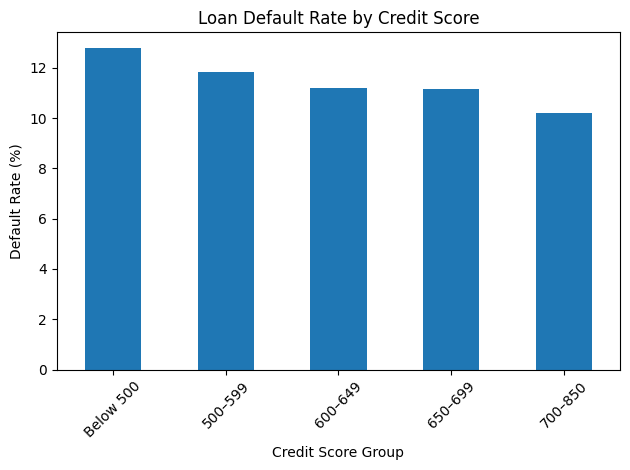

In [ ]:

import matplotlib.pyplot as plt

credit_default.plot(kind="bar")

plt.title("Loan Default Rate by Credit Score")
plt.xlabel("Credit Score Group")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:

# Group borrowers by their DTI ratio
df["DTI_Group"] = pd.cut(
    df["DTIRatio"],
    bins=[0, 0.2, 0.4, 0.6, 0.8, 1.0],
    labels=["0.0–0.2", "0.2–0.4", "0.4–0.6", "0.6–0.8", "0.8–1.0"],
    include_lowest=True
)

# Calculate the default rate for each group
dti_default_rate = df.groupby(
    "DTI_Group", observed=False
)["Default"].mean() * 100

print(dti_default_rate.round(2))

DTI_Group
0.0–0.2    10.36
0.2–0.4    11.16
0.4–0.6    11.82
0.6–0.8    12.24
0.8–1.0    12.18
Name: Default, dtype: float64


In [ ]:


plt.figure(figsize=(10, 5))

bars = plt.bar(
    dti_default_rate.index.astype(str),
    dti_default_rate.values
)

# Display the exact percentage above each bar
plt.bar_label(bars, fmt="%.2f%%", padding=4)

plt.title("Loan Default Rate by Debt-to-Income Ratio")
plt.xlabel("DTI Group")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:

# Display summary statistics for borrower income
df["Income"].describe()

,Income
count,255347.000000
mean,82499.304597
std,38963.013729
min,15000.000000
25%,48825.500000
50%,82466.000000
75%,116219.000000
max,149999.000000


In [ ]:

# Divide borrowers into four income groups
df["Income_Group"] = pd.qcut(
    df["Income"],
    q=4,
    labels=["Low", "Lower-Middle", "Upper-Middle", "High"],
    duplicates="drop"
)

# Calculate the default rate for each income group
income_default_rate = (
    df.groupby("Income_Group", observed=False)["Default"].mean() * 100
)

print(income_default_rate.round(2))

Income_Group
Low             17.38
Lower-Middle    10.54
Upper-Middle     9.51
High             9.02
Name: Default, dtype: float64


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

# Divide borrowers into four income groups
df["Income_Group"] = pd.qcut(
    df["Income"],
    q=4,
    labels=["Low", "Lower-Middle", "Upper-Middle", "High"]
)

# Show the income range for each group
income_summary = df.groupby(
    "Income_Group", observed=False
)["Income"].agg(["min", "max", "count"])

print(income_summary)

                 min     max  count
Income_Group                       
Low            15000   48825  63837
Lower-Middle   48826   82466  63837
Upper-Middle   82467  116219  63839
High          116220  149999  63834


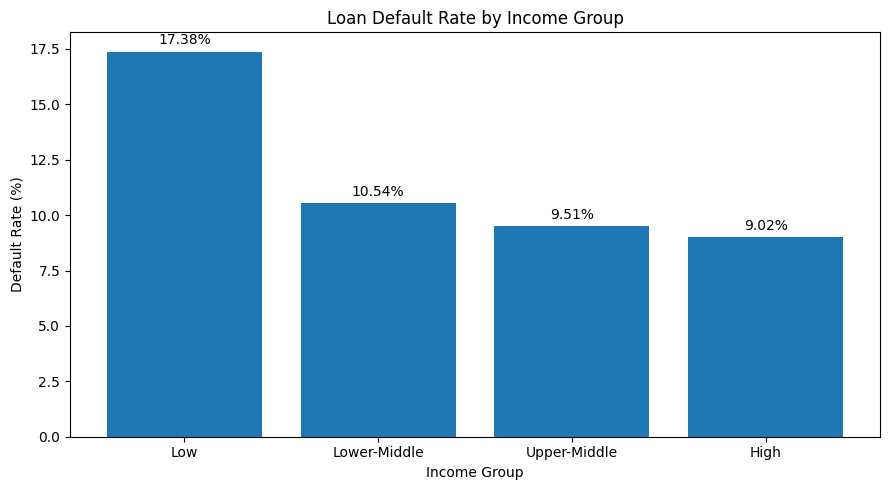

In [ ]:

# Calculate the default rate for each income group
income_default_rate = (
    df.groupby("Income_Group", observed=False)["Default"].mean() * 100
)

# Create a clearly labelled chart
plt.figure(figsize=(9, 5))

bars = plt.bar(
    income_default_rate.index.astype(str),
    income_default_rate.values
)

plt.bar_label(bars, fmt="%.2f%%", padding=3)
plt.title("Loan Default Rate by Income Group")
plt.xlabel("Income Group")
plt.ylabel("Default Rate (%)")
plt.tight_layout()
plt.show()

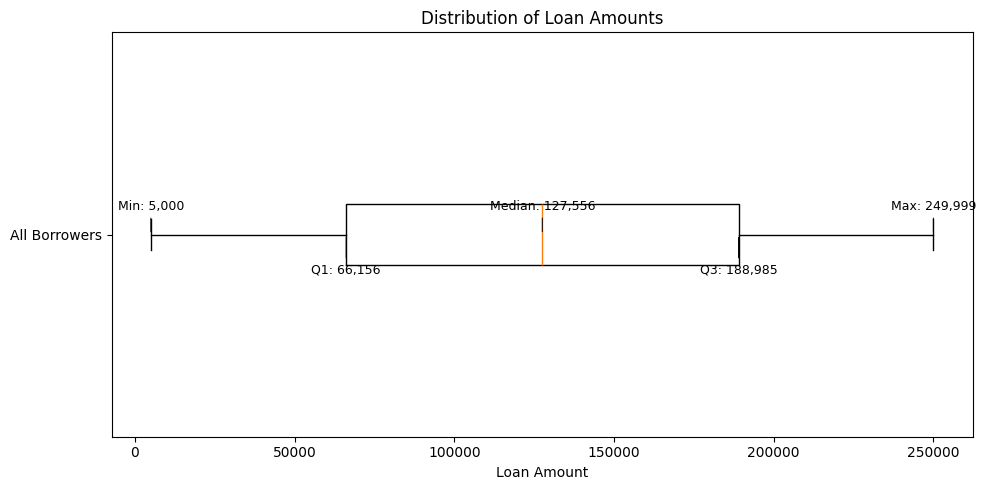

In [ ]:


import matplotlib.pyplot as plt

# Remove missing loan amounts
loan_amounts = df["LoanAmount"].dropna()

# Calculate the key numerical values
minimum = loan_amounts.min()
q1 = loan_amounts.quantile(0.25)
median = loan_amounts.median()
q3 = loan_amounts.quantile(0.75)
maximum = loan_amounts.max()

# Create the box plot
plt.figure(figsize=(10, 5))
plt.boxplot(loan_amounts, vert=False)

# Label the five key values
values = [
    (minimum, f"Min: {minimum:,.0f}"),
    (q1, f"Q1: {q1:,.0f}"),
    (median, f"Median: {median:,.0f}"),
    (q3, f"Q3: {q3:,.0f}"),
    (maximum, f"Max: {maximum:,.0f}")
]

for value, label in values:
    plt.annotate(
        label,
        xy=(value, 1),
        xytext=(0, 18 if value in [minimum, median, maximum] else -28),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        arrowprops=dict(arrowstyle="-", lw=0.7)
    )

plt.title("Distribution of Loan Amounts")
plt.xlabel("Loan Amount")
plt.yticks([1], ["All Borrowers"])
plt.tight_layout()
plt.show()

In [ ]:


import pandas as pd
import matplotlib.pyplot as plt

# Divide interest rates into four groups
df["InterestRate_Group"] = pd.qcut(
    df["InterestRate"],
    q=4,
    labels=["Low", "Lower-Middle", "Upper-Middle", "High"],
    duplicates="drop"
)

# Calculate default rate for each group
interest_default_rate = (
    df.groupby("InterestRate_Group", observed=False)["Default"].mean() * 100
)

print(interest_default_rate.round(2))

InterestRate_Group
Low              6.57
Lower-Middle     9.44
Upper-Middle    12.96
High            17.50
Name: Default, dtype: float64


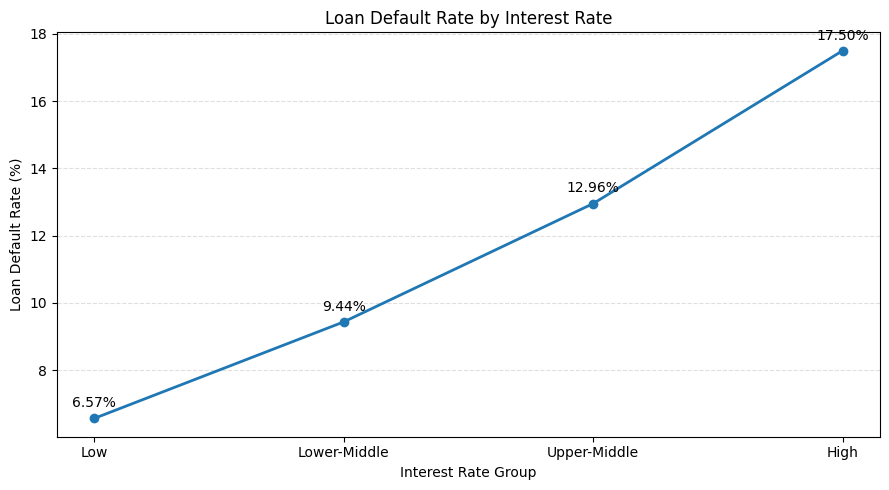

In [ ]:


plt.figure(figsize=(9, 5))

plt.plot(
    interest_default_rate.index.astype(str),
    interest_default_rate.values,
    marker="o",
    linewidth=2
)

# Show the actual percentage at each point
for i, value in enumerate(interest_default_rate.values):
    plt.annotate(
        f"{value:.2f}%",
        (i, value),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center"
    )

plt.title("Loan Default Rate by Interest Rate")
plt.xlabel("Interest Rate Group")
plt.ylabel("Loan Default Rate (%)")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [ ]:

loan_term_default = (
    df.groupby("LoanTerm")["Default"]
    .agg(you["mean", "count"])
)

loan_term_default["Default Rate (%)"] = loan_term_default["mean"] * 100

loan_term_default = loan_term_default[
    ["count", "Default Rate (%)"]
]

print(loan_term_default.round(2))

          count  Default Rate (%)
LoanTerm                         
12        50957             11.62
24        51009             11.61
36        51061             11.57
48        51166             11.57
60        51154             11.70


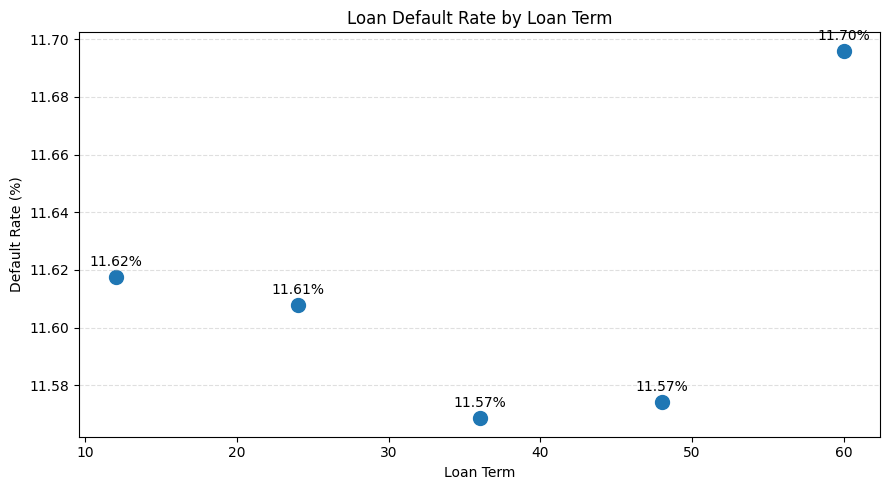

In [ ]:

plt.figure(figsize=(9, 5))

plt.scatter(
    loan_term_default.index,
    loan_term_default["Default Rate (%)"],
    s=100
)

for term, rate in zip(
    loan_term_default.index,
    loan_term_default["Default Rate (%)"]
):
    plt.annotate(
        f"{rate:.2f}%",
        (term, rate),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center"
    )

plt.title("Loan Default Rate by Loan Term")
plt.xlabel("Loan Term")
plt.ylabel("Default Rate (%)")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [ ]:

loan_purpose_rate = (
    df.groupby("LoanPurpose")["Default"]
    .mean()
    .mul(100)
    .sort_values(ascending=True)
)

print(loan_purpose_rate.round(2))

LoanPurpose
Home         10.23
Other        11.79
Education    11.84
Auto         11.88
Business     12.33
Name: Default, dtype: float64


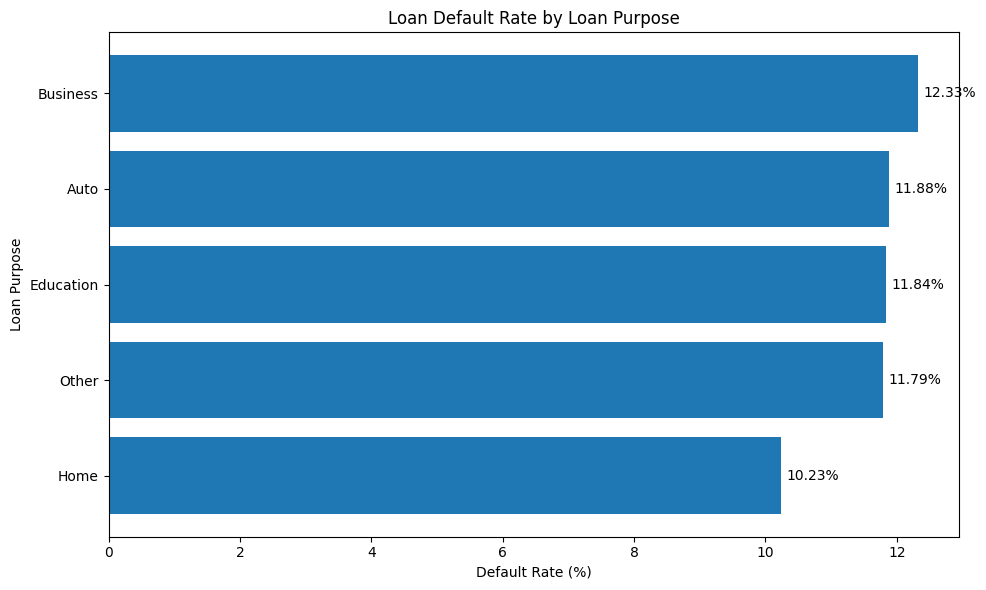

In [ ]:

plt.figure(figsize=(10, 6))

bars = plt.barh(
    loan_purpose_rate.index.astype(str),
    loan_purpose_rate.values
)

plt.bar_label(bars, fmt="%.2f%%", padding=4)

plt.title("Loan Default Rate by Loan Purpose")
plt.xlabel("Default Rate (%)")
plt.ylabel("Loan Purpose")
plt.tight_layout()
plt.show()

In [ ]:

default_counts = df["Default"].value_counts().sort_index()

default_labels = [
    "No Default" if value == 0 else "Default"
    for value in default_counts.index
]

print(default_counts)
print("\nPercentages:")
print((default_counts / len(df) * 100).round(2))

Default
0    225694
1     29653
Name: count, dtype: int64

Percentages:
Default
0    88.39
1    11.61
Name: count, dtype: float64


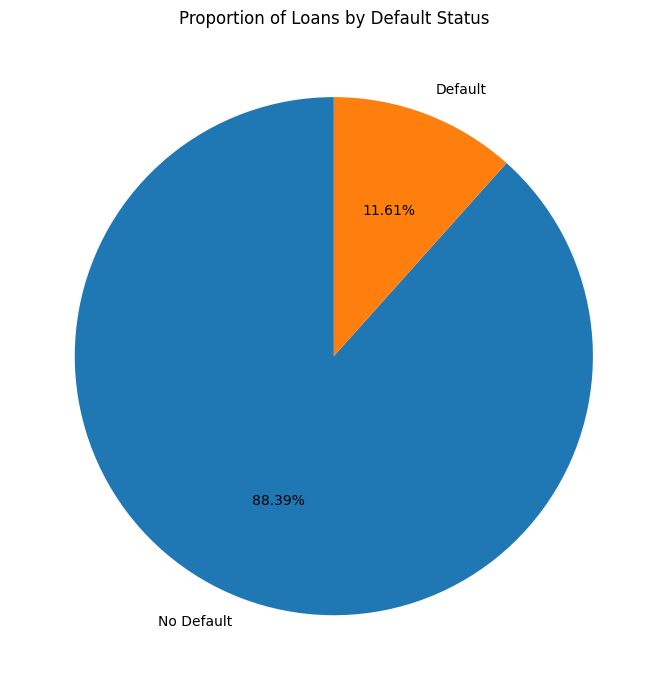

In [ ]:

plt.figure(figsize=(7, 7))

plt.pie(
    default_counts,
    labels=default_labels,
    autopct="%1.2f%%",
    startangle=90
)

plt.title("Proportion of Loans by Default Status")
plt.tight_layout()
plt.show()

In [ ]:
print(df["CreditScore"].describe().round(2))

count    255347.00
mean        574.26
std         158.90
min         300.00
25%         437.00
50%         574.00
75%         712.00
max         849.00
Name: CreditScore, dtype: float64


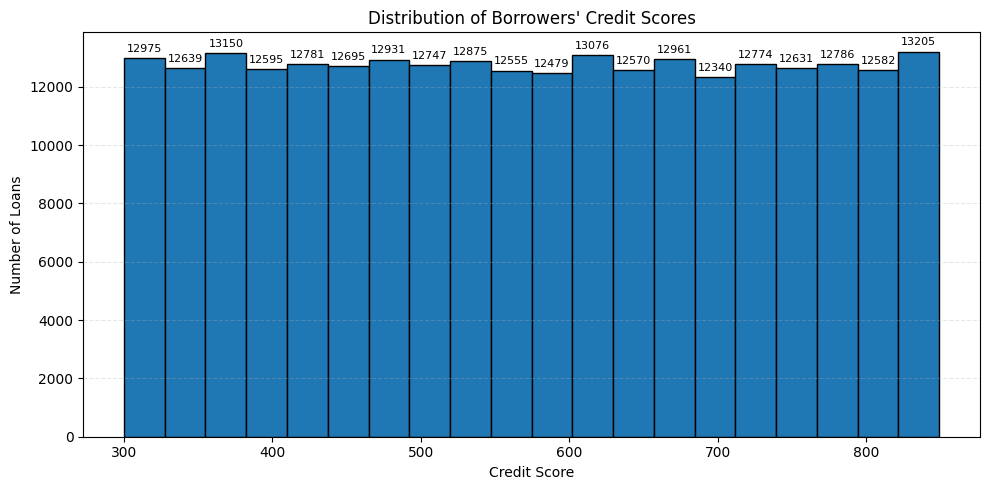

In [ ]:

plt.figure(figsize=(10, 5))

counts, bins, patches = plt.hist(
    df["CreditScore"].dropna(),
    bins=20,
    edgecolor="black"
)

# Display the count above each bar
plt.bar_label(
    patches,
    labels=[str(int(count)) for count in counts],
    padding=3,
    fontsize=8
)

plt.title("Distribution of Borrowers' Credit Scores")
plt.xlabel("Credit Score")
plt.ylabel("Number of Loans")
plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
age_bins = [0, 25, 35, 45, 55, 100]
age_labels = [
    "Under 25",
    "25–34",
    "35–44",
    "45–54",
    "55 and above"
]

df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=age_bins,
    labels=age_labels,
    right=False
)

age_default_rate = (
    df.groupby("AgeGroup", observed=False)["Default"]
    .mean() * 100
)

print(age_default_rate.round(2))

AgeGroup
Under 25        21.03
25–34           16.56
35–44           11.98
45–54            8.75
55 and above     5.59
Name: Default, dtype: float64


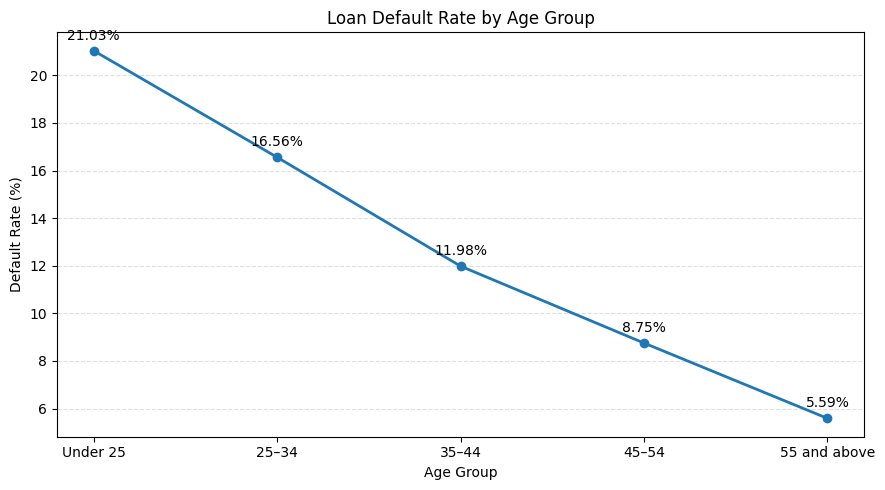

In [ ]:

plt.figure(figsize=(9, 5))

plt.plot(
    age_default_rate.index.astype(str),
    age_default_rate.values,
    marker="o",
    linewidth=2
)

for i, value in enumerate(age_default_rate.values):
    plt.annotate(
        f"{value:.2f}%",
        (i, value),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center"
    )

plt.title("Loan Default Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Default Rate (%)")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [ ]:

education_default_rate = (
    df.groupby("Education")["Default"]
    .mean()
    .mul(100)
    .sort_values()
)

print("Default Rate by Education (%)")
print(education_default_rate.round(2))

Default Rate by Education (%)
Education
PhD            10.59
Master's       10.87
Bachelor's     12.10
High School    12.88
Name: Default, dtype: float64


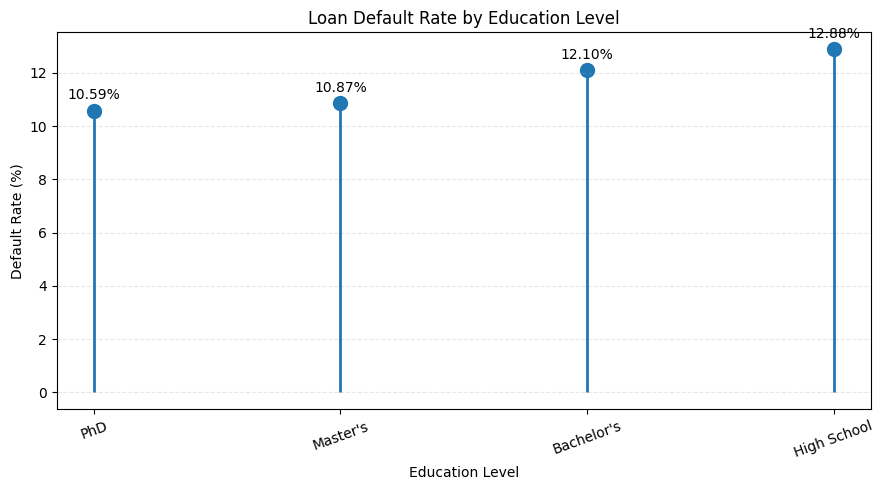

In [ ]:

plt.figure(figsize=(9, 5))

x = range(len(education_default_rate))

plt.vlines(
    x,
    ymin=0,
    ymax=education_default_rate.values,
    linewidth=2
)

plt.scatter(
    x,
    education_default_rate.values,
    s=100
)

for i, value in enumerate(education_default_rate.values):
    plt.annotate(
        f"{value:.2f}%",
        (i, value),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center"
    )

plt.xticks(x, education_default_rate.index.astype(str), rotation=20)
plt.title("Loan Default Rate by Education Level")
plt.xlabel("Education Level")
plt.ylabel("Default Rate (%)")
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:

marital_default_rate = (
    df.groupby("MaritalStatus")["Default"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

print("Loan Default Rate by Marital Status (%)")
print(marital_default_rate.round(2))

Loan Default Rate by Marital Status (%)
MaritalStatus
Divorced    12.53
Single      11.91
Married     10.40
Name: Default, dtype: float64


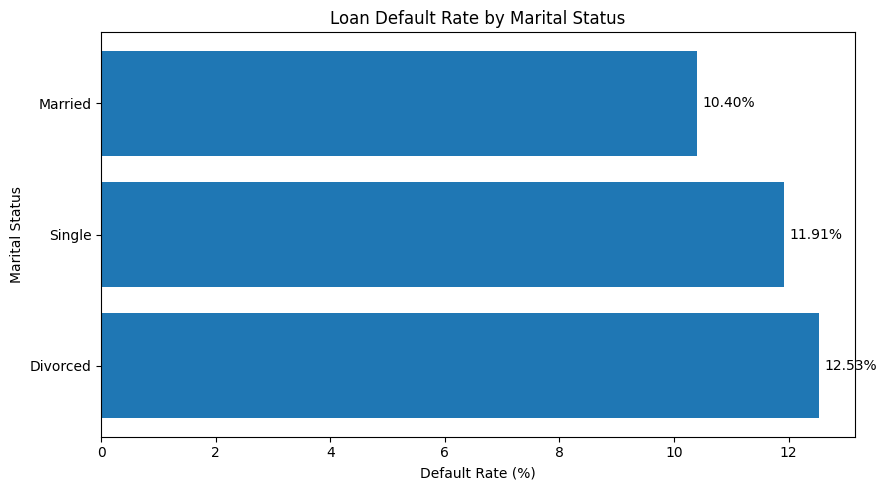

In [ ]:

plt.figure(figsize=(9, 5))

bars = plt.barh(
    marital_default_rate.index.astype(str),
    marital_default_rate.values
)

plt.bar_label(bars, fmt="%.2f%%", padding=4)

plt.title("Loan Default Rate by Marital Status")
plt.xlabel("Default Rate (%)")
plt.ylabel("Marital Status")
plt.tight_layout()
plt.show()

In [ ]:

mortgage_counts = pd.crosstab(
    df["HasMortgage"],
    df["Default"]
)

mortgage_counts.columns = [
    "No Default" if col == 0 else "Default"
    for col in mortgage_counts.columns
]

print(mortgage_counts)

             No Default  Default
HasMortgage                     
No               111909    15761
Yes              113785    13892


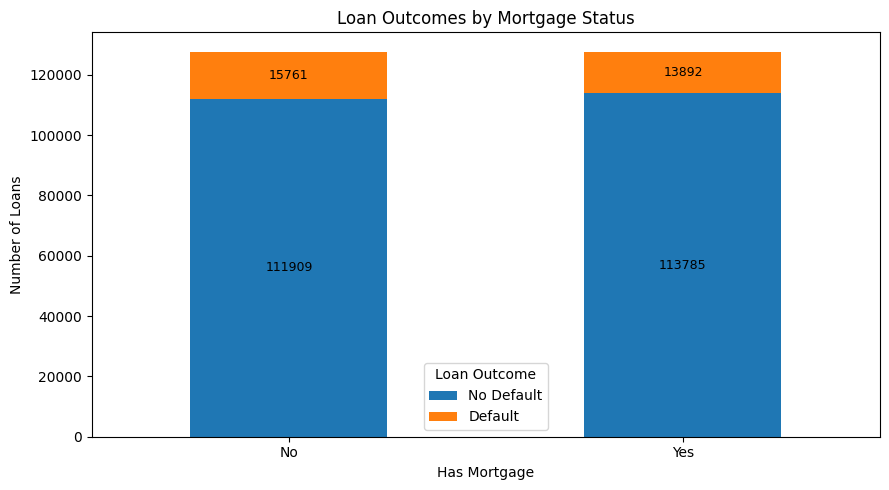

In [ ]:

ax = mortgage_counts.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

for container in ax.containers:
    ax.bar_label(
        container,
        label_type="center",
        fmt="%d",
        fontsize=9
    )

plt.title("Loan Outcomes by Mortgage Status")
plt.xlabel("Has Mortgage")
plt.ylabel("Number of Loans")
plt.xticks(rotation=0)
plt.legend(title="Loan Outcome")
plt.tight_layout()
plt.show()

In [ ]:
cosigner_default_rate = (
    df.groupby("HasCoSigner")["Default"]
    .mean()
    .mul(100)
)

print("Default Rate by Co-Signer Status (%)")
print(cosigner_default_rate.round(2))

Default Rate by Co-Signer Status (%)
HasCoSigner
No     12.87
Yes    10.36
Name: Default, dtype: float64


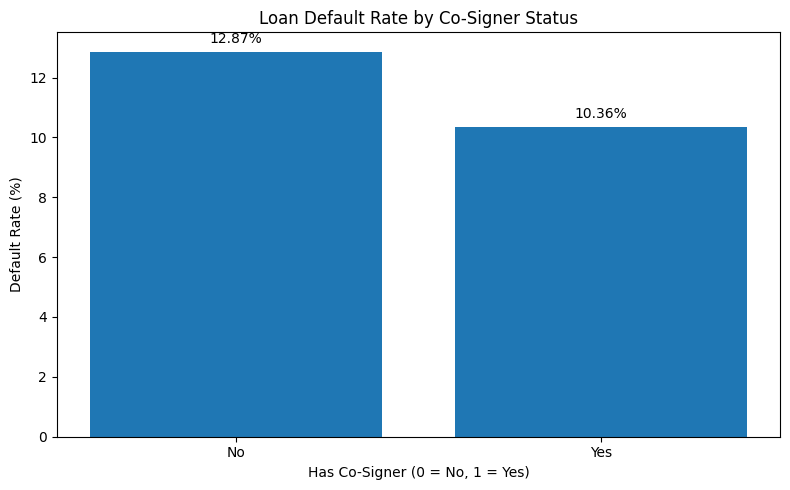

In [ ]:

plt.figure(figsize=(8, 5))

bars = plt.bar(
    cosigner_default_rate.index.astype(str),
    cosigner_default_rate.values
)

plt.bar_label(bars, fmt="%.2f%%", padding=4)

plt.title("Loan Default Rate by Co-Signer Status")
plt.xlabel("Has Co-Signer (0 = No, 1 = Yes)")
plt.ylabel("Default Rate (%)")
plt.tight_layout()
plt.show()

In [ ]:

df["IncomeGroup"] = pd.qcut(
    df["Income"],
    q=4,
    labels=["Low Income", "Lower-Middle", "Upper-Middle", "High Income"],
    duplicates="drop"
)

income_default_rate = (
    df.groupby("IncomeGroup", observed=False)["Default"]
    .mean()
    .mul(100)
)

print("Loan Default Rate by Income Group (%)")
print(income_default_rate.round(2))

Loan Default Rate by Income Group (%)
IncomeGroup
Low Income      17.38
Lower-Middle    10.54
Upper-Middle     9.51
High Income      9.02
Name: Default, dtype: float64


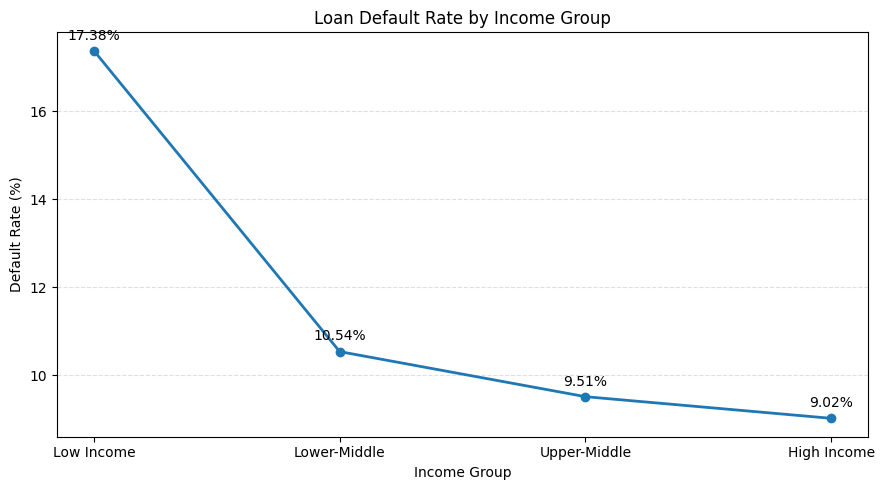

In [ ]:

plt.figure(figsize=(9, 5))

plt.plot(
    income_default_rate.index.astype(str),
    income_default_rate.values,
    marker="o",
    linewidth=2
)

for i, value in enumerate(income_default_rate.values):
    plt.annotate(
        f"{value:.2f}%",
        (i, value),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center"
    )

plt.title("Loan Default Rate by Income Group")
plt.xlabel("Income Group")
plt.ylabel("Default Rate (%)")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [ ]:

# Check missing values
print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal duplicate rows:")
print(df.duplicated().sum())

print("\nDataset dimensions:")
print(df.shape)

print("\nData types:")
print(df.dtypes)

Missing values in each column:
LoanID                0
Age                   0
Income                0
LoanAmount            0
CreditScore           0
MonthsEmployed        0
NumCreditLines        0
InterestRate          0
LoanTerm              0
DTIRatio              0
Education             0
EmploymentType        0
MaritalStatus         0
HasMortgage           0
HasDependents         0
LoanPurpose           0
HasCoSigner           0
Default               0
DTI_Group             0
Income_Group          0
LoanAmountGroup       0
InterestRate_Group    0
AgeGroup              0
IncomeGroup           0
dtype: int64

Total duplicate rows:
0

Dataset dimensions:
(255347, 24)

Data types:
LoanID                  object
Age                      int64
Income                   int64
LoanAmount               int64
CreditScore              int64
MonthsEmployed           int64
NumCreditLines           int64
InterestRate           float64
LoanTerm                 int64
DTIRatio               float6

In [ ]:
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes.to_string())

print("\nUnique values in important columns:")
for col in ["Default", "HasMortgage", "HasDependents", "HasCoSigner"]:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False))

Column names:
['LoanID', 'Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed', 'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio', 'Education', 'EmploymentType', 'MaritalStatus', 'HasMortgage', 'HasDependents', 'LoanPurpose', 'HasCoSigner', 'Default', 'DTI_Group', 'Income_Group', 'LoanAmountGroup', 'InterestRate_Group', 'AgeGroup', 'IncomeGroup']

Data types:
LoanID                  object
Age                      int64
Income                   int64
LoanAmount               int64
CreditScore              int64
MonthsEmployed           int64
NumCreditLines           int64
InterestRate           float64
LoanTerm                 int64
DTIRatio               float64
Education               object
EmploymentType          object
MaritalStatus           object
HasMortgage             object
HasDependents           object
LoanPurpose             object
HasCoSigner             object
Default                  int64
DTI_Group             category
Income_Group          category
Lo

In [ ]:

columns_to_check = [
    "Age",
    "Income",
    "LoanAmount",
    "CreditScore",
    "MonthsEmployed",
    "NumCreditLines",
    "InterestRate",
    "LoanTerm",
    "DTIRatio"
]

print(df[columns_to_check].describe().round(2).to_string())

             Age     Income  LoanAmount  CreditScore  MonthsEmployed  NumCreditLines  InterestRate   LoanTerm   DTIRatio
count  255347.00  255347.00   255347.00    255347.00       255347.00       255347.00     255347.00  255347.00  255347.00
mean       43.50   82499.30   127578.87       574.26           59.54            2.50         13.49      36.03       0.50
std        14.99   38963.01    70840.71       158.90           34.64            1.12          6.64      16.97       0.23
min        18.00   15000.00     5000.00       300.00            0.00            1.00          2.00      12.00       0.10
25%        31.00   48825.50    66156.00       437.00           30.00            2.00          7.77      24.00       0.30
50%        43.00   82466.00   127556.00       574.00           60.00            2.00         13.46      36.00       0.50
75%        56.00  116219.00   188985.00       712.00           90.00            3.00         19.25      48.00       0.70
max        69.00  149999.00   24

In [ ]:

print("Default values:", sorted(df["Default"].unique()))

print("\nNegative values in numerical columns:")
numeric_cols = [
    "Age", "Income", "LoanAmount", "CreditScore",
    "MonthsEmployed", "NumCreditLines", "InterestRate",
    "LoanTerm", "DTIRatio"
]

print((df[numeric_cols] < 0).sum())

print("\nCategory values:")
for col in ["HasMortgage", "HasDependents", "HasCoSigner"]:
    print(f"{col}: {sorted(df[col].dropna().unique())}")

Default values: [np.int64(0), np.int64(1)]

Negative values in numerical columns:
Age               0
Income            0
LoanAmount        0
CreditScore       0
MonthsEmployed    0
NumCreditLines    0
InterestRate      0
LoanTerm          0
DTIRatio          0
dtype: int64

Category values:
HasMortgage: ['No', 'Yes']
HasDependents: ['No', 'Yes']
HasCoSigner: ['No', 'Yes']


In [ ]:
!pip install plotly

In [ ]:

# Dashboard summary metrics

total_loans = len(df)
defaulted_loans = (df["Default"] == 1).sum()
non_defaulted_loans = (df["Default"] == 0).sum()
default_rate = df["Default"].mean() * 100

print("LOAN DEFAULT ANALYSIS DASHBOARD")
print("-" * 35)
print(f"Total Loans: {total_loans:,}")
print(f"Defaulted Loans: {defaulted_loans:,}")
print(f"Non-Defaulted Loans: {non_defaulted_loans:,}")
print(f"Overall Default Rate: {default_rate:.2f}%")

LOAN DEFAULT ANALYSIS DASHBOARD
-----------------------------------
Total Loans: 255,347
Defaulted Loans: 29,653
Non-Defaulted Loans: 225,694
Overall Default Rate: 11.61%


In [ ]:

import plotly.graph_objects as go
from plotly.subplots import make_subplots

fig = make_subplots(
    rows=2,
    cols=2,
    specs=[
        [{"type": "indicator"}, {"type": "indicator"}],
        [{"type": "indicator"}, {"type": "indicator"}]
    ],
    subplot_titles=(
        "Total Loans",
        "Defaulted Loans",
        "Non-Defaulted Loans",
        "Default Rate"
    ),
    vertical_spacing=0.30,
    horizontal_spacing=0.15
)

metrics = [
    (total_loans, 1, 1, ",.0f", ""),
    (defaulted_loans, 1, 2, ",.0f", ""),
    (non_defaulted_loans, 2, 1, ",.0f", ""),
    (default_rate, 2, 2, ".2f", "%")
]

for value, row, col, number_format, suffix in metrics:
    fig.add_trace(
        go.Indicator(
            mode="number",
            value=value,
            number={
                "valueformat": number_format,
                "suffix": suffix,
                "font": {"size": 25}
            }
        ),
        row=row,
        col=col
    )

fig.update_layout(
    title={
        "text": "Loan Default Analysis Dashboard",
        "x": 0.5
    },
    height=500,
    width=650,
    margin=dict(l=30, r=30, t=100, b=30)
)

fig.show()

In [ ]:

import plotly.express as px

employment_default = (
    df.groupby("EmploymentType")["Default"]
    .mean()
    .mul(100)
    .reset_index(name="DefaultRate")
)

fig = px.bar(
    employment_default,
    x="EmploymentType",
    y="DefaultRate",
    text="DefaultRate",
    title="Loan Default Rate by Employment Type",
    labels={
        "EmploymentType": "Employment Type",
        "DefaultRate": "Default Rate (%)"
    },
    hover_data={"DefaultRate": ":.2f"}
)

fig.update_traces(
    texttemplate="%{text:.2f}%",
    textposition="outside"
)

fig.update_layout(
    yaxis_title="Default Rate (%)",
    xaxis_title="Employment Type",
    yaxis_ticksuffix="%",
    uniformtext_minsize=10,
    uniformtext_mode="hide",
    height=450
)

fig.show()

In [ ]:

import plotly.express as px

employment_default = (
    df.groupby("EmploymentType")["Default"]
    .mean()
    .mul(100)
    .reset_index(name="DefaultRate")
)

employment_default["Label"] = (
    employment_default["DefaultRate"].map(lambda x: f"{x:.2f}%")
)

fig = px.bar(
    employment_default,
    x="EmploymentType",
    y="DefaultRate",
    text="Label",
    title="Loan Default Rate by Employment Type",
    labels={
        "EmploymentType": "Employment Type",
        "DefaultRate": "Default Rate (%)"
    }
)

fig.update_traces(
    textposition="outside",
    textfont_size=13,
    cliponaxis=False,
    hovertemplate=(
        "Employment: %{x}<br>"
        "Default Rate: %{y:.2f}%"
        "<extra></extra>"
    )
)

fig.update_layout(
    height=500,
    width=650,
    yaxis=dict(
        title="Default Rate (%)",
        ticksuffix="%",
        rangemode="tozero"
    ),
    xaxis_title="Employment Type",
    margin=dict(t=80, b=80, l=60, r=40)
)

fig.show()

In [ ]:

import plotly.express as px
import ipywidgets as widgets
from IPython.display import display, clear_output

# Dropdown filter
purpose_dropdown = widgets.Dropdown(
    options=["All Loan Purposes"] + sorted(df["LoanPurpose"].dropna().unique().tolist()),
    value="All Loan Purposes",
    description="Loan purpose:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="350px")
)

output = widgets.Output()

def update_purpose_chart(change=None):
    with output:
        clear_output(wait=True)

        if purpose_dropdown.value == "All Loan Purposes":
            filtered_df = df
        else:
            filtered_df = df[
                df["LoanPurpose"] == purpose_dropdown.value
            ]

        purpose_rates = (
            filtered_df.groupby("LoanPurpose")["Default"]
            .mean()
            .mul(100)
            .reset_index(name="DefaultRate")
        )

        purpose_rates["Label"] = purpose_rates["DefaultRate"].map(
            lambda value: f"{value:.2f}%"
        )

        fig = px.bar(
            purpose_rates,
            x="LoanPurpose",
            y="DefaultRate",
            text="Label",
            title="Loan Default Rate by Loan Purpose",
            labels={
                "LoanPurpose": "Loan Purpose",
                "DefaultRate": "Default Rate (%)"
            }
        )

        fig.update_traces(
            textposition="outside",
            cliponaxis=False,
            hovertemplate=(
                "Loan Purpose: %{x}<br>"
                "Default Rate: %{y:.2f}%<extra></extra>"
            )
        )

        fig.update_layout(
            height=450,
            yaxis_title="Default Rate (%)",
            xaxis_title="Loan Purpose",
            yaxis_ticksuffix="%",
            margin=dict(t=80, b=80)
        )

        fig.show()

purpose_dropdown.observe(update_purpose_chart, names="value")

display(purpose_dropdown, output)
update_purpose_chart()

Dropdown(description='Loan purpose:', layout=Layout(width='350px'), options=('All Loan Purposes', 'Auto', 'Bus…

Output()

In [ ]:

import plotly.express as px

# Calculate the default rate for each loan purpose
purpose_rates = (
    df.groupby("LoanPurpose")["Default"]
    .mean()
    .mul(100)
    .reset_index(name="DefaultRate")
)

# Add readable percentage labels
purpose_rates["Label"] = purpose_rates["DefaultRate"].apply(
    lambda x: f"{x:.2f}%"
)

# Sort from highest to lowest default rate
purpose_rates = purpose_rates.sort_values(
    "DefaultRate", ascending=True
)

# Create a clear horizontal bar chart
fig = px.bar(
    purpose_rates,
    x="DefaultRate",
    y="LoanPurpose",
    orientation="h",
    text="Label",
    title="Loan Default Rate by Loan Purpose",
    labels={
        "DefaultRate": "Default Rate (%)",
        "LoanPurpose": "Purpose of Loan"
    }
)

fig.update_traces(
    textposition="outside",
    cliponaxis=False,
    hovertemplate=(
        "Loan Purpose: %{y}<br>"
        "Default Rate: %{x:.2f}%"
        "<extra></extra>"
    )
)

fig.update_layout(
    width=800,
    height=500,
    title_x=0.5,
    font=dict(size=13),
    xaxis=dict(
        title="Default Rate (%)",
        ticksuffix="%",
        rangemode="tozero"
    ),
    yaxis_title="Purpose of Loan",
    margin=dict(l=120, r=80, t=80, b=70)
)

fig.show()

In [ ]:

print("DATASET")
print("Shape:", df.shape)

print("\nCOLUMNS")
print(df.columns.tolist())

print("\nDASHBOARD LIBRARIES")
try:
    import plotly.express as px
    print("Plotly: Available")
except ImportError:
    print("Plotly: Not installed")

print("\nDEFAULT SUMMARY")
print(df["Default"].value_counts())

print("\nDEFAULT RATE")
print(f"{df['Default'].mean() * 100:.2f}%")

DATASET
Shape: (255347, 24)

COLUMNS
['LoanID', 'Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed', 'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio', 'Education', 'EmploymentType', 'MaritalStatus', 'HasMortgage', 'HasDependents', 'LoanPurpose', 'HasCoSigner', 'Default', 'DTI_Group', 'Income_Group', 'LoanAmountGroup', 'InterestRate_Group', 'AgeGroup', 'IncomeGroup']

DASHBOARD LIBRARIES
Plotly: Available

DEFAULT SUMMARY
Default
0    225694
1     29653
Name: count, dtype: int64

DEFAULT RATE
11.61%


In [ ]:
%whos

Variable                 Type            Data/Info
--------------------------------------------------
age_bins                 list            n=6
age_default_rate         Series          AgeGroup\nUnder 25       <...>: Default, dtype: float64
age_labels               list            n=5
ax                       Axes            Axes(0.10767,0.116556;0.875664x0.808778)
bar                      Rectangle       Rectangle(xy=(2.6, 0), wi<...> height=9.46337, angle=0)
bars                     BarContainer    <BarContainer object of 2 artists>
bins                     ndarray         21: 21 elems, type `float64`, 168 bytes
clear_output             function        <function clear_output at 0x7f1fc2c52ca0>
col                      int             2
columns_to_check         list            n=9
container                BarContainer    <BarContainer object of 2 artists>
cosigner_default_rate    Series          HasCoSigner\nNo     12.86<...>: Default, dtype: float64
counts                   ndarra

In [ ]:

print("KPI metrics:", kpis)
print("\nLoan-purpose categories:")
print(purpose_rates["LoanPurpose"].tolist())
print("\nLoan-term results:")
print(loan_term_default.head(10))

KPI metrics: [('Total Loans', '255,347'), ('Defaulted Loans', '29,653'), ('Non-Defaulted Loans', '225,694'), ('Default Rate', '11.61%')]

Loan-purpose categories:
['Home', 'Other', 'Education', 'Auto', 'Business']

Loan-term results:
          count  Default Rate (%)
LoanTerm                         
12        50957         11.617638
24        51009         11.607755
36        51061         11.568516
48        51166         11.574092
60        51154         11.696055


In [ ]:

for i, cell in enumerate(In[1:], start=1):
    if any(word in cell for word in [
        "plt.", "px.", "go.", "fig.show",
        "sns.", "make_subplots"
    ]):
        print(f"\n--- Cell {i} ---")
        print(cell[:250])


--- Cell 10 ---
import matplotlib.pyplot as plt

# Create the DTI default rate chart
dti_default_rate.plot(kind="bar", figsize=(9, 5))

# Add chart titles and labels
plt.title("Loan Default Rate by Debt-to-Income Ratio")
plt.xlabel("Debt-to-Income (DTI) Group")
plt.

--- Cell 13 ---
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.hist(df["Income"], bins=30, edgecolor="black")

plt.title("Distribution of Borrower Income")
plt.xlabel("Income")
plt.ylabel("Number of Borrowers")

plt.tight_layout()
plt.show()

--- Cell 14 ---
import matplotlib.pyplot as plt

income_default_rate.plot(kind="bar", figsize=(9, 5))

plt.title("Loan Default Rate by Income Group")
plt.xlabel("Income Group")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

--- Cell 16 ---
# Calculate the default rate for each income group
income_default_rate = (
    df.groupby("Income_Group", observed=False)["Default"].mean() * 100
)

# Create a clearly labelled chart
plt.figur

In [ ]:

# Key findings for the Loan Default Analysis project

overall_rate = df["Default"].mean() * 100

print("=" * 50)
print("LOAN DEFAULT ANALYSIS: KEY FINDINGS")
print("=" * 50)

print(f"\nTotal loan records: {len(df):,}")
print(f"Defaulted loans: {(df['Default'] == 1).sum():,}")
print(f"Non-defaulted loans: {(df['Default'] == 0).sum():,}")
print(f"Overall default rate: {overall_rate:.2f}%")

# Compare default rates across important categories
categories = [
    "CreditScoreGroup",
    "EmploymentType",
    "LoanPurpose",
    "Education",
    "MaritalStatus",
    "HasMortgage",
    "HasDependents",
    "HasCoSigner"
]

for column in categories:
    if column in df.columns:
        rates = (
            df.groupby(column, observed=True)["Default"]
            .mean()
            .mul(100)
            .sort_values(ascending=False)
        )

        print(f"\n--- Default Rate by {column} ---")
        print(rates.round(2).to_string())

LOAN DEFAULT ANALYSIS: KEY FINDINGS

Total loan records: 255,347
Defaulted loans: 29,653
Non-defaulted loans: 225,694
Overall default rate: 11.61%

--- Default Rate by EmploymentType ---
EmploymentType
Unemployed       13.55
Part-time        11.97
Self-employed    11.46
Full-time         9.46

--- Default Rate by LoanPurpose ---
LoanPurpose
Business     12.33
Auto         11.88
Education    11.84
Other        11.79
Home         10.23

--- Default Rate by Education ---
Education
High School    12.88
Bachelor's     12.10
Master's       10.87
PhD            10.59

--- Default Rate by MaritalStatus ---
MaritalStatus
Divorced    12.53
Single      11.91
Married     10.40

--- Default Rate by HasMortgage ---
HasMortgage
No     12.35
Yes    10.88

--- Default Rate by HasDependents ---
HasDependents
No     12.72
Yes    10.50

--- Default Rate by HasCoSigner ---
HasCoSigner
No     12.87
Yes    10.36


In [ ]:

import pandas as pd

# Calculate default rates across important categories
categories = [
    "CreditScoreGroup",
    "EmploymentType",
    "LoanPurpose",
    "Education",
    "MaritalStatus",
    "HasMortgage",
    "HasDependents",
    "HasCoSigner"
]

results = []

for column in categories:
    if column in df.columns:
        summary = (
            df.groupby(column, observed=True)["Default"]
            .agg(["count", "mean"])
            .reset_index()
        )

        summary.columns = [
            "Category",
            "Loan_Count",
            "Default_Rate"
        ]

        summary["Default_Rate"] = (
            summary["Default_Rate"] * 100
        ).round(2)

        summary.insert(0, "Analysis", column)
        results.append(summary)

findings_table = pd.concat(results, ignore_index=True)

# Display the results
display(findings_table)

# Save the results for your project
findings_table.to_csv(
    "loan_default_findings.csv",
    index=False
)

print("Findings summary saved successfully.")

,Analysis,Category,Loan_Count,Default_Rate
0,EmploymentType,Full-time,63656,9.46
1,EmploymentType,Part-time,64161,11.97
2,EmploymentType,Self-employed,63706,11.46
3,EmploymentType,Unemployed,63824,13.55
4,LoanPurpose,Auto,50844,11.88
5,LoanPurpose,Business,51298,12.33
6,LoanPurpose,Education,51005,11.84
7,LoanPurpose,Home,51286,10.23
8,LoanPurpose,Other,50914,11.79
9,Education,Bachelor's,64366,12.10


Findings summary saved successfully.


In [ ]:

import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# --------------------------------
# 1. Calculate dashboard KPIs
# --------------------------------
total_loans = len(df)
defaulted_loans = int((df["Default"] == 1).sum())
non_defaulted_loans = int((df["Default"] == 0).sum())
default_rate = df["Default"].mean() * 100

# --------------------------------
# 2. Create a dashboard layout
# --------------------------------
fig = make_subplots(
    rows=4,
    cols=2,
    specs=[
        [{"type": "indicator"}, {"type": "indicator"}],
        [{"type": "indicator"}, {"type": "indicator"}],
        [{"type": "xy"}, {"type": "xy"}],
        [{"type": "xy"}, {"type": "xy"}]
    ],
    subplot_titles=(
        "", "",
        "", "",
        "Default Rate by Credit Score",
        "Default Rate by Employment Type",
        "Default Rate by Loan Purpose",
        "Default Rate by Age Group"
    ),
    vertical_spacing=0.12,
    horizontal_spacing=0.15
)

# --------------------------------
# 3. Add four KPI indicators
# --------------------------------
kpis = [
    ("Total Loans", total_loans, ","),
    ("Defaulted Loans", defaulted_loans, ","),
    ("Non-Defaulted Loans", non_defaulted_loans, ","),
    ("Overall Default Rate", default_rate, ".2f")
]

for i, (label, value, fmt) in enumerate(kpis):
    row = i // 2 + 1
    col = i % 2 + 1

    fig.add_trace(
        go.Indicator(
            mode="number",
            value=value,
            title={"text": label},
            number={
                "valueformat": fmt,
                "suffix": "%" if label == "Overall Default Rate" else ""
            }
        ),
        row=row,
        col=col
    )

# --------------------------------
# 4. Helper to calculate default rates
# --------------------------------
def get_rates(column):
    result = (
        df.groupby(column, observed=True)["Default"]
        .mean()
        .mul(100)
        .reset_index(name="Rate")
    )
    result["Label"] = result["Rate"].map(lambda x: f"{x:.2f}%")
    return result

# Credit score
credit = get_rates("CreditScoreGroup").sort_values("Rate")

fig.add_trace(
    go.Bar(
        x=credit["CreditScoreGroup"],
        y=credit["Rate"],
        text=credit["Label"],
        textposition="outside",
        name="Credit Score",
        hovertemplate="%{x}<br>Default rate: %{y:.2f}%<extra></extra>"
    ),
    row=3, col=1
)

# Employment type
employment = get_rates("EmploymentType").sort_values("Rate")

fig.add_trace(
    go.Bar(
        x=employment["EmploymentType"],
        y=employment["Rate"],
        text=employment["Label"],
        textposition="outside",
        name="Employment Type",
        hovertemplate="%{x}<br>Default rate: %{y:.2f}%<extra></extra>"
    ),
    row=3, col=2
)

# Loan purpose
purpose = get_rates("LoanPurpose").sort_values("Rate")

fig.add_trace(
    go.Bar(
        x=purpose["LoanPurpose"],
        y=purpose["Rate"],
        text=purpose["Label"],
        textposition="outside",
        name="Loan Purpose",
        hovertemplate="%{x}<br>Default rate: %{y:.2f}%<extra></extra>"
    ),
    row=4, col=1
)

# Age group
age = get_rates("AgeGroup").sort_values("AgeGroup")

fig.add_trace(
    go.Bar(
        x=age["AgeGroup"],
        y=age["Rate"],
        text=age["Label"],
        textposition="outside",
        name="Age Group",
        hovertemplate="%{x}<br>Default rate: %{y:.2f}%<extra></extra>"
    ),
    row=4, col=2
)

# --------------------------------
# 5. Improve readability
# --------------------------------
fig.update_layout(
    title={
        "text": "LOAN DEFAULT ANALYSIS DASHBOARD",
        "x": 0.5
    },
    height=1500,
    width=1100,
    showlegend=False,
    template="plotly_white",
    margin=dict(t=120, b=100, l=70, r=50)
)

fig.update_yaxes(
    title_text="Default Rate (%)",
    ticksuffix="%",
    rangemode="tozero"
)

fig.update_xaxes(tickangle=-25)

# Display the dashboard
fig.show()

NameError: name 'df' is not defined

In [ ]:

print("Is df available?", "df" in globals())
print("Available dataset variables:",
      [name for name, value in globals().items()
       if isinstance(value, pd.DataFrame)])

Is df available? False
Available dataset variables: []


In [ ]:

import pandas as pd
from google.colab import files

# Upload your existing Excel dataset
uploaded_file = files.upload()

# Read the uploaded Excel file
file_name = next(iter(uploaded_file))
df = pd.read_excel(file_name)

# Confirm that the dataset loaded correctly
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

In [ ]:

import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# 1. Check that the dataset is loaded
if "df" not in globals():
    raise NameError("Please run your dataset-loading cell first.")

required = [
    "Default", "CreditScore", "EmploymentType",
    "LoanPurpose", "Age"
]
missing = [c for c in required if c not in df.columns]

if missing:
    raise ValueError(f"Missing dataset columns: {missing}")

# 2. Restore grouping columns if needed
if "CreditScoreGroup" not in df.columns:
    df["CreditScoreGroup"] = pd.cut(
        df["CreditScore"],
        bins=[299, 499, 599, 649, 699, 850],
        labels=[
            "Below 500", "500–599", "600–649",
            "650–699", "700–850"
        ]
    )

if "AgeGroup" not in df.columns:
    df["AgeGroup"] = pd.cut(
        df["Age"],
        bins=[17, 24, 34, 44, 54, 64, 100],
        labels=[
            "Under 25", "25–34", "35–44",
            "45–54", "55–64", "65+"
        ]
    )

# 3. Calculate the KPI values
total_loans = len(df)
defaulted_loans = int(df["Default"].sum())
non_defaulted_loans = int((df["Default"] == 0).sum())
default_rate = df["Default"].mean() * 100

# 4. Create dashboard layout
fig = make_subplots(
    rows=3,
    cols=2,
    specs=[
        [{"type": "indicator"}, {"type": "indicator"}],
        [{"type": "indicator"}, {"type": "indicator"}],
        [{"type": "xy"}, {"type": "xy"}]
    ],
    subplot_titles=(
        "", "",
        "", "",
        "Default Rate by Credit Score",
        "Default Rate by Employment Type"
    ),
    vertical_spacing=0.14,
    horizontal_spacing=0.14
)

# 5. Add four KPI indicators
kpis = [
    ("Total Loans", total_loans, ","),
    ("Defaulted Loans", defaulted_loans, ","),
    ("Non-Defaulted Loans", non_defaulted_loans, ","),
    ("Overall Default Rate", default_rate, ".2f")
]

for i, (label, value, fmt) in enumerate(kpis):
    fig.add_trace(
        go.Indicator(
            mode="number",
            value=value,
            title={"text": label},
            number={
                "valueformat": fmt,
                "suffix": "%" if label == "Overall Default Rate" else ""
            }
        ),
        row=i // 2 + 1,
        col=i % 2 + 1
    )

# 6. Function to calculate default rate by category
def calculate_rates(column):
    result = (
        df.groupby(column, observed=True)["Default"]
        .mean()
        .mul(100)
        .reset_index(name="Rate")
        .dropna()
        .sort_values("Rate")
    )
    result["Label"] = result["Rate"].map(lambda x: f"{x:.2f}%")
    return result

# 7. Credit score chart
credit = calculate_rates("CreditScoreGroup")

fig.add_trace(
    go.Bar(
        x=credit["Rate"],
        y=credit["CreditScoreGroup"].astype(str),
        orientation="h",
        text=credit["Label"],
        textposition="outside",
        cliponaxis=False,
        hovertemplate="%{y}<br>Default rate: %{x:.2f}%<extra></extra>"
    ),
    row=3, col=1
)

# 8. Employment type chart
employment = calculate_rates("EmploymentType")

fig.add_trace(
    go.Bar(
        x=employment["Rate"],
        y=employment["EmploymentType"].astype(str),
        orientation="h",
        text=employment["Label"],
        textposition="outside",
        cliponaxis=False,
        hovertemplate="%{y}<br>Default rate: %{x:.2f}%<extra></extra>"
    ),
    row=3, col=2
)

# 9. Dashboard formatting
fig.update_layout(
    title={
        "text": "LOAN DEFAULT ANALYSIS DASHBOARD",
        "x": 0.5
    },
    template="plotly_white",
    height=1200,
    width=1000,
    showlegend=False,
    margin=dict(t=110, b=70, l=90, r=80)
)

fig.update_xaxes(
    title_text="Default Rate (%)",
    ticksuffix="%",
    rangemode="tozero",
    row=3
)

fig.show()

In [ ]:

import pandas as pd
from google.colab import files

# Upload your existing Excel dataset
uploaded_file = files.upload()

# Read the uploaded Excel file
file_name = next(iter(uploaded_file))
df = pd.read_excel(file_name)

# Confirm that the dataset loaded correctly
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

Saving Loan_default perfect.xlsx to Loan_default perfect.xlsx
Dataset loaded successfully!
Dataset shape: (255347, 18)
Columns: ['LoanID', 'Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed', 'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio', 'Education', 'EmploymentType', 'MaritalStatus', 'HasMortgage', 'HasDependents', 'LoanPurpose', 'HasCoSigner', 'Default']


In [ ]:

import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Calculate KPIs
total_loans = len(df)
defaulted_loans = int((df["Default"] == 1).sum())
non_defaulted_loans = int((df["Default"] == 0).sum())
default_rate = df["Default"].mean() * 100

# Restore groups if needed
if "CreditScoreGroup" not in df.columns:
    df["CreditScoreGroup"] = pd.cut(
        df["CreditScore"],
        bins=[299, 499, 599, 649, 699, 850],
        labels=["Below 500", "500–599", "600–649", "650–699", "700–850"]
    )

if "AgeGroup" not in df.columns:
    df["AgeGroup"] = pd.cut(
        df["Age"],
        bins=[17, 24, 34, 44, 54, 64, 100],
        labels=["Under 25", "25–34", "35–44", "45–54", "55–64", "65+"]
    )

# Dashboard layout: 4 KPI cards + 6 charts
fig = make_subplots(
    rows=5, cols=2,
    specs=[
        [{"type": "indicator"}, {"type": "indicator"}],
        [{"type": "indicator"}, {"type": "indicator"}],
        [{"type": "xy"}, {"type": "xy"}],
        [{"type": "xy"}, {"type": "xy"}],
        [{"type": "xy"}, {"type": "xy"}]
    ],
    subplot_titles=(
        "", "", "", "",
        "Default Rate by Credit Score",
        "Default Rate by Employment Type",
        "Default Rate by Loan Purpose",
        "Default Rate by Age Group",
        "Default Rate by Education",
        "Default Rate by Marital Status"
    ),
    vertical_spacing=0.09,
    horizontal_spacing=0.16
)

# KPI cards
kpis = [
    ("Total Loans", total_loans, ","),
    ("Defaulted Loans", defaulted_loans, ","),
    ("Non-Defaulted Loans", non_defaulted_loans, ","),
    ("Default Rate", default_rate, ".2f")
]

for i, (label, value, fmt) in enumerate(kpis):
    fig.add_trace(
        go.Indicator(
            mode="number",
            value=value,
            title={"text": label},
            number={
                "valueformat": fmt,
                "suffix": "%" if label == "Default Rate" else "",
                "font": {"size": 25}
            }
        ),
        row=i // 2 + 1, col=i % 2 + 1
    )

# Helper for default rates
def rates_for(column):
    result = (
        df.groupby(column, observed=True)["Default"]
        .mean().mul(100)
        .reset_index(name="Rate")
        .dropna()
    )
    result["Label"] = result["Rate"].map(lambda x: f"{x:.2f}%")
    return result.sort_values("Rate")

# Six charts
chart_specs = [
    ("CreditScoreGroup", 3, 1),
    ("EmploymentType", 3, 2),
    ("LoanPurpose", 4, 1),
    ("AgeGroup", 4, 2),
    ("Education", 5, 1),
    ("MaritalStatus", 5, 2)
]

for column, row, col in chart_specs:
    data = rates_for(column)

    fig.add_trace(
        go.Bar(
            x=data["Rate"],
            y=data[column].astype(str),
            orientation="h",
            text=data["Label"],
            textposition="outside",
            cliponaxis=False,
            hovertemplate=(
                column + ": %{y}<br>"
                "Default rate: %{x:.2f}%<extra></extra>"
            )
        ),
        row=row, col=col
    )

fig.update_layout(
    title=dict(
        text="LOAN DEFAULT ANALYSIS DASHBOARD",
        x=0.5, font=dict(size=18)
    ),
    template="plotly_white",
    height=1500,
    width=850,
    showlegend=False,
    font=dict(size=10),
    margin=dict(t=100, b=50, l=80, r=65)
)

fig.update_annotations(font_size=11)
fig.update_xaxes(
    title_text="Default Rate (%)",
    ticksuffix="%",
    rangemode="tozero"
)

fig.show()

In [ ]:

import pandas as pd
from google.colab import files

# Upload your existing Excel dataset
uploaded_file = files.upload()

# Read the uploaded Excel file
file_name = next(iter(uploaded_file))
df = pd.read_excel(file_name)

# Confirm that the dataset loaded correctly
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

Saving Loan_default perfect.xlsx to Loan_default perfect.xlsx
Dataset loaded successfully!
Dataset shape: (255347, 18)
Columns: ['LoanID', 'Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed', 'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio', 'Education', 'EmploymentType', 'MaritalStatus', 'HasMortgage', 'HasDependents', 'LoanPurpose', 'HasCoSigner', 'Default']


In [ ]:


print("Is df available?", "df" in globals())
print("Available dataset variables:",
      [name for name, value in globals().items()
       if isinstance(value, pd.DataFrame)])

Is df available? True
Available dataset variables: ['df']


In [ ]:
%whos

Variable             Type         Data/Info
-------------------------------------------
col                  int          1
column               str          CreditScoreGroup
columns_to_analyse   list         n=6
df                   DataFrame                LoanID  Age  <...>255347 rows x 18 columns]
file_name            str          Loan_default perfect.xlsx
files                module       <module 'google.colab.fil<...>s/google/colab/files.py'>
pd                   module       <module 'pandas' from '/u<...>ages/pandas/__init__.py'>
row                  int          1
uploaded_file        dict         n=1


In [ ]:

import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# =====================================
# 1. PREPARE THE DATA
# =====================================

# Recreate Credit Score Groups
df["CreditScoreGroup"] = pd.cut(
    df["CreditScore"],
    bins=[299, 499, 599, 649, 699, 850],
    labels=["Below 500", "500–599", "600–649", "650–699", "700–850"]
)

# Recreate Age Groups
df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=[17, 24, 34, 44, 54, 64, 100],
    labels=["Under 25", "25–34", "35–44", "45–54", "55–64", "65+"]
)

# =====================================
# 2. CALCULATE KPI VALUES
# =====================================

total_loans = len(df)
defaulted_loans = int(df["Default"].sum())
non_defaulted_loans = total_loans - defaulted_loans
default_rate = df["Default"].mean() * 100

# =====================================
# 3. CREATE DASHBOARD LAYOUT
# =====================================

fig = make_subplots(
    rows=5,
    cols=2,
    specs=[
        [{"type": "indicator"}, {"type": "indicator"}],
        [{"type": "indicator"}, {"type": "indicator"}],
        [{"type": "xy"}, {"type": "xy"}],
        [{"type": "xy"}, {"type": "xy"}],
        [{"type": "xy"}, {"type": "xy"}]
    ],
    subplot_titles=[
        "", "", "", "",
        "Default Rate by Credit Score",
        "Default Rate by Employment Type",
        "Default Rate by Loan Purpose",
        "Default Rate by Age Group",
        "Default Rate by Education",
        "Default Rate by Marital Status"
    ],
    vertical_spacing=0.09,
    horizontal_spacing=0.16
)

# =====================================
# 4. ADD FOUR KPI CARDS
# =====================================

kpis = [
    ("Total Loans", total_loans, ""),
    ("Defaulted Loans", defaulted_loans, ""),
    ("Non-Defaulted Loans", non_defaulted_loans, ""),
    ("Default Rate", default_rate, "%")
]

positions = [(1, 1), (1, 2), (2, 1), (2, 2)]

for (label, value, suffix), (r, c) in zip(kpis, positions):
    fig.add_trace(
        go.Indicator(
            mode="number",
            value=value,
            number={
                "suffix": suffix,
                "valueformat": ".2f" if suffix == "%" else ","
            },
            title={"text": label}
        ),
        row=r,
        col=c
    )

# =====================================
# 5. FUNCTION TO CALCULATE DEFAULT RATES
# =====================================

def rates_for(column):
    result = (
        df.groupby(column, observed=True)["Default"]
        .mean()
        .mul(100)
        .reset_index(name="Rate")
        .dropna()
    )

    result[column] = result[column].astype(str)
    return result

# =====================================
# 6. ADD SIX DASHBOARD CHARTS
# =====================================

chart_specs = [
    ("CreditScoreGroup", 3, 1),
    ("EmploymentType", 3, 2),
    ("LoanPurpose", 4, 1),
    ("AgeGroup", 4, 2),
    ("Education", 5, 1),
    ("MaritalStatus", 5, 2)
]

for column, r, c in chart_specs:

    chart_data = rates_for(column)

    fig.add_trace(
        go.Bar(
            x=chart_data["Rate"],
            y=chart_data[column],
            orientation="h",
            text=chart_data["Rate"].round(2).astype(str) + "%",
            textposition="outside",
            showlegend=False
        ),
        row=r,
        col=c
    )

# =====================================
# 7. STYLE THE COMPLETE DASHBOARD
# =====================================

fig.update_layout(
    title={
        "text": "LOAN DEFAULT ANALYSIS DASHBOARD",
        "x": 0.5,
        "font": {"size": 18}
    },
    height=1500,
    width=850,
    template="plotly_white",
    font={"size": 10},
    margin={"l": 100, "r": 60, "t": 100, "b": 60}
)

# Hide percentage scale numbers but keep axis titles
fig.update_xaxes(
    showticklabels=False,
    ticks="",
    showgrid=False,
    title_text="Default Rate (%)"
)

fig.update_annotations(font_size=11)

# =====================================
# 8. DISPLAY DASHBOARD
# =====================================

fig.show()

In [ ]:
fig.show()

NameError: name 'fig' is not defined

In [ ]:

columns_to_analyse = [
    "CreditScoreGroup",
    "EmploymentType",
    "LoanPurpose",
    "AgeGroup",
    "Education",
    "MaritalStatus"
]

for column in columns_to_analyse:
    result = (
        df.groupby(column, observed=True)["Default"]
        .mean()
        .mul(100)
        .sort_values(ascending=False)
    )

    print("\n", "=" * 40)
    print(column)
    print("=" * 40)

    print(
        "Highest default rate:",
        result.index[0],
        "-", round(result.iloc[0], 2), "%"
    )

    print(
        "Lowest default rate:",
        result.index[-1],
        "-", round(result.iloc[-1], 2), "%"
    )


CreditScoreGroup
Highest default rate: Below 500 - 12.77 %
Lowest default rate: 700–850 - 10.21 %

EmploymentType
Highest default rate: Unemployed - 13.55 %
Lowest default rate: Full-time - 9.46 %

LoanPurpose
Highest default rate: Business - 12.33 %
Lowest default rate: Home - 10.23 %

AgeGroup
Highest default rate: Under 25 - 21.03 %
Lowest default rate: 65+ - 4.85 %

Education
Highest default rate: High School - 12.88 %
Lowest default rate: PhD - 10.59 %

MaritalStatus
Highest default rate: Divorced - 12.53 %
Lowest default rate: Married - 10.4 %


In [ ]:

for column in columns_to_analyse:
    print("\n", "=" * 40)
    print(column)
    print("=" * 40)

    summary = (
        df.groupby(column, observed=True)["Default"]
        .agg(
            Total_Borrowers="count",
            Defaulted_Borrowers="sum",
            Default_Rate="mean"
        )
    )

    summary["Default_Rate"] = (
        summary["Default_Rate"] * 100
    ).round(2)

    print(summary)


CreditScoreGroup
                  Total_Borrowers  Defaulted_Borrowers  Default_Rate
CreditScoreGroup                                                    
Below 500                   93029                11883         12.77
500–599                     46454                 5494         11.83
600–649                     23283                 2607         11.20
650–699                     23151                 2583         11.16
700–850                     69430                 7086         10.21

EmploymentType
                Total_Borrowers  Defaulted_Borrowers  Default_Rate
EmploymentType                                                    
Full-time                 63656                 6024          9.46
Part-time                 64161                 7677         11.97
Self-employed             63706                 7302         11.46
Unemployed                63824                 8650         13.55

LoanPurpose
             Total_Borrowers  Defaulted_Borrowers  Default_Rate
Loan

In [ ]:


print("Is df available?", "df" in globals())
print("Available dataset variables:",
      [name for name, value in globals().items()
       if isinstance(value, pd.DataFrame)])

Is df available? False


NameError: name 'pd' is not defined

In [ ]:

import pandas as pd
from google.colab import files

# Upload your existing Excel dataset
uploaded_file = files.upload()

# Read the uploaded Excel file
file_name = next(iter(uploaded_file))
df = pd.read_excel(file_name)

# Confirm that the dataset loaded correctly
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

Saving Loan_default perfect.xlsx to Loan_default perfect.xlsx
Dataset loaded successfully!
Dataset shape: (255347, 18)
Columns: ['LoanID', 'Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed', 'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio', 'Education', 'EmploymentType', 'MaritalStatus', 'HasMortgage', 'HasDependents', 'LoanPurpose', 'HasCoSigner', 'Default']


In [ ]:

single_borrowers = df[df["MaritalStatus"] == "Single"]

total = len(single_borrowers)
defaults = single_borrowers["Default"].sum()
rate = single_borrowers["Default"].mean() * 100

print("Single Borrowers")
print("Total borrowers:", total)
print("Defaulted borrowers:", defaults)
print("Default rate:", round(rate, 2), "%")

Single Borrowers
Total borrowers: 85012
Defaulted borrowers: 10127
Default rate: 11.91 %


In [ ]:


print("Is df available?", "df" in globals())
print("Available dataset variables:",
      [name for name, value in globals().items()
       if isinstance(value, pd.DataFrame)])

Is df available? True
Available dataset variables: ['df', 'single_borrowers']


In [ ]:
import os
import traceback

try:
    output_path = "/content/Loan_Default_Analysis_Dashboard.html"

    fig.write_html(
        output_path,
        full_html=True,
        include_plotlyjs=True
    )

    print("Export completed!")
    print("File exists:", os.path.exists(output_path))
    print("File size:", os.path.getsize(output_path), "bytes")

except Exception:
    traceback.print_exc()

Traceback (most recent call last):
  File "/tmp/ipykernel_2565/2564354830.py", line 7, in <cell line: 0>
    fig.write_html(
    ^^^
NameError: name 'fig' is not defined


In [ ]:

from google.colab import files
files.download("/content/Loan_Default_Analysis_Dashboard.html")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

from google.colab import files

files.download("/content/Loan_Default_Analysis_Dashboard.html")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import ipywidgets as widgets
from IPython.display import display, clear_output

# Recreate groups if necessary
if "CreditScoreGroup" not in df.columns:
    df["CreditScoreGroup"] = pd.cut(
        df["CreditScore"],
        bins=[299, 499, 599, 649, 699, 850],
        labels=["Below 500", "500–599", "600–649", "650–699", "700–850"]
    )

if "AgeGroup" not in df.columns:
    df["AgeGroup"] = pd.cut(
        df["Age"],
        bins=[17, 24, 34, 44, 54, 64, 100],
        labels=["Under 25", "25–34", "35–44", "45–54", "55–64", "65+"]
    )

# Create slicers
employment_filter = widgets.Dropdown(
    options=["All"] + sorted(df["EmploymentType"].dropna().unique().tolist()),
    value="All",
    description="Employment:"
)

purpose_filter = widgets.Dropdown(
    options=["All"] + sorted(df["LoanPurpose"].dropna().unique().tolist()),
    value="All",
    description="Loan Purpose:"
)

age_filter = widgets.Dropdown(
    options=["All"] + df["AgeGroup"].dropna().astype(str).unique().tolist(),
    value="All",
    description="Age Group:"
)

credit_filter = widgets.Dropdown(
    options=["All"] + df["CreditScoreGroup"].dropna().astype(str).unique().tolist(),
    value="All",
    description="Credit Score:"
)

output = widgets.Output()

def update_dashboard(change=None):

    filtered = df.copy()

    if employment_filter.value != "All":
        filtered = filtered[
            filtered["EmploymentType"] == employment_filter.value
        ]

    if purpose_filter.value != "All":
        filtered = filtered[
            filtered["LoanPurpose"] == purpose_filter.value
        ]

    if age_filter.value != "All":
        filtered = filtered[
            filtered["AgeGroup"].astype(str) == age_filter.value
        ]

    if credit_filter.value != "All":
        filtered = filtered[
            filtered["CreditScoreGroup"].astype(str) == credit_filter.value
        ]

    with output:
        clear_output(wait=True)

        if filtered.empty:
            print("No borrowers match these filter selections.")
            return

        total = len(filtered)
        defaults = int(filtered["Default"].sum())
        non_defaults = total - defaults
        rate = filtered["Default"].mean() * 100

        fig = make_subplots(
            rows=5,
            cols=2,
            specs=[
                [{"type": "indicator"}, {"type": "indicator"}],
                [{"type": "indicator"}, {"type": "indicator"}],
                [{"type": "xy"}, {"type": "xy"}],
                [{"type": "xy"}, {"type": "xy"}],
                [{"type": "xy"}, {"type": "xy"}]
            ],
            subplot_titles=[
                "", "", "", "",
                "Default Rate by Credit Score",
                "Default Rate by Employment",
                "Default Rate by Loan Purpose",
                "Default Rate by Age",
                "Default Rate by Education",
                "Default Rate by Marital Status"
            ],
            vertical_spacing=0.09,
            horizontal_spacing=0.16
        )

        kpis = [
            ("Total Loans", total, ""),
            ("Defaulted Loans", defaults, ""),
            ("Non-Defaulted Loans", non_defaults, ""),
            ("Default Rate", rate, "%")
        ]

        positions = [(1,1), (1,2), (2,1), (2,2)]

        for (label, value, suffix), (r,c) in zip(kpis, positions):
            fig.add_trace(
                go.Indicator(
                    mode="number",
                    value=value,
                    number={
                        "suffix": suffix,
                        "valueformat": ".2f" if suffix == "%" else ","
                    },
                    title={"text": label}
                ),
                row=r, col=c
            )

        chart_specs = [
            ("CreditScoreGroup", 3, 1),
            ("EmploymentType", 3, 2),
            ("LoanPurpose", 4, 1),
            ("AgeGroup", 4, 2),
            ("Education", 5, 1),
            ("MaritalStatus", 5, 2)
        ]

        for column, r, c in chart_specs:
            result = (
                filtered.groupby(column, observed=True)["Default"]
                .mean()
                .mul(100)
                .reset_index(name="Rate")
                .dropna()
            )

            result[column] = result[column].astype(str)

            fig.add_trace(
                go.Bar(
                    x=result["Rate"],
                    y=result[column],
                    orientation="h",
                    text=result["Rate"].round(2).astype(str) + "%",
                    textposition="outside",
                    showlegend=False
                ),
                row=r, col=c
            )

        fig.update_layout(
            title="INTERACTIVE LOAN DEFAULT DASHBOARD",
            height=1500,
            width=850,
            template="plotly_white",
            font={"size": 10}
        )

        fig.update_xaxes(
            showticklabels=False,
            ticks="",
            showgrid=False,
            title_text="Default Rate (%)"
        )

        fig.show()

# Connect slicers to dashboard
for control in [
    employment_filter,
    purpose_filter,
    age_filter,
    credit_filter
]:
    control.observe(update_dashboard, names="value")

display(
    widgets.VBox([
        widgets.HTML("<h3>Loan Default Dashboard Filters</h3>"),
        employment_filter,
        purpose_filter,
        age_filter,
        credit_filter,
        output
    ])
)

update_dashboard()

In [ ]:

import json
from google.colab import files

# Recreate groups if missing
if "CreditScoreGroup" not in df.columns:
    df["CreditScoreGroup"] = pd.cut(
        df["CreditScore"],
        bins=[299, 499, 599, 649, 699, 850],
        labels=["Below 500", "500–599", "600–649", "650–699", "700–850"]
    )

if "AgeGroup" not in df.columns:
    df["AgeGroup"] = pd.cut(
        df["Age"],
        bins=[17, 24, 34, 44, 54, 64, 100],
        labels=["Under 25", "25–34", "35–44", "45–54", "55–64", "65+"]
    )

# Prepare data for the standalone dashboard
data_json = df[
    [
        "Default", "CreditScoreGroup", "EmploymentType",
        "LoanPurpose", "AgeGroup", "Education", "MaritalStatus"
    ]
].to_json(orient="records")

html = r"""
<!DOCTYPE html>
<html>
<head>
<meta charset="UTF-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>Loan Default Analysis Dashboard</title>
<script src="https://cdn.plot.ly/plotly-2.35.2.min.js"></script>

<style>
body {
    font-family: Arial, sans-serif;
    margin: 0;
    padding: 15px;
    background: #f4f6fa;
    color: #222;
}
h1 {
    text-align: center;
    font-size: 22px;
}
.filters, .kpis, .charts {
    display: grid;
    gap: 12px;
    margin-bottom: 18px;
}
.filters {
    grid-template-columns: repeat(2, minmax(0, 1fr));
    background: white;
    padding: 14px;
    border-radius: 10px;
}
label {
    font-size: 12px;
    font-weight: bold;
}
select {
    width: 100%;
    padding: 10px;
    margin-top: 6px;
    border: 1px solid #ccc;
    border-radius: 6px;
    background: white;
}
.kpis {
    grid-template-columns: repeat(2, minmax(0, 1fr));
}
.kpi {
    background: white;
    padding: 15px 8px;
    border-radius: 10px;
    text-align: center;
}
.kpi strong {
    display: block;
    font-size: 23px;
    margin-bottom: 5px;
}
.kpi span {
    font-size: 12px;
    color: #666;
}
.charts {
    grid-template-columns: 1fr;
}
.chart {
    background: white;
    padding: 8px;
    border-radius: 10px;
    min-width: 0;
}
.chart div {
    width: 100%;
    height: 320px;
}
button {
    padding: 10px;
    border: 0;
    border-radius: 6px;
    background: #263b65;
    color: white;
    font-weight: bold;
}
@media (min-width: 750px) {
    .filters { grid-template-columns: repeat(4, 1fr); }
    .kpis { grid-template-columns: repeat(4, 1fr); }
    .charts { grid-template-columns: repeat(2, minmax(0, 1fr)); }
}
</style>
</head>

<body>

<h1>LOAN DEFAULT ANALYSIS DASHBOARD</h1>

<div class="filters">
    <div>
        <label>Employment Type</label>
        <select id="employment"><option value="All">All</option></select>
    </div>
    <div>
        <label>Loan Purpose</label>
        <select id="purpose"><option value="All">All</option></select>
    </div>
    <div>
        <label>Age Group</label>
        <select id="age"><option value="All">All</option></select>
    </div>
    <div>
        <label>Credit Score Group</label>
        <select id="credit"><option value="All">All</option></select>
    </div>
    <button onclick="resetFilters()" style="grid-column:1/-1">
        Reset All Filters
    </button>
</div>

<div class="kpis">
    <div class="kpi"><strong id="total">0</strong><span>Total Loans</span></div>
    <div class="kpi"><strong id="defaults">0</strong><span>Defaulted Loans</span></div>
    <div class="kpi"><strong id="nondefaults">0</strong><span>Non-Defaulted Loans</span></div>
    <div class="kpi"><strong id="rate">0%</strong><span>Default Rate</span></div>
</div>

<div class="charts">
    <div class="chart"><div id="chart1"></div></div>
    <div class="chart"><div id="chart2"></div></div>
    <div class="chart"><div id="chart3"></div></div>
    <div class="chart"><div id="chart4"></div></div>
    <div class="chart"><div id="chart5"></div></div>
    <div class="chart"><div id="chart6"></div></div>
</div>

<script>
const data = DATA_PLACEHOLDER;

const filters = [
    ["employment", "EmploymentType"],
    ["purpose", "LoanPurpose"],
    ["age", "AgeGroup"],
    ["credit", "CreditScoreGroup"]
];

filters.forEach(([id, column]) => {
    const select = document.getElementById(id);
    [...new Set(data.map(d => d[column]).filter(v => v !== null))]
        .sort()
        .forEach(value => {
            const option = document.createElement("option");
            option.value = value;
            option.textContent = value;
            select.appendChild(option);
        });
    select.addEventListener("change", updateDashboard);
});

const chartSpecs = [
    ["CreditScoreGroup", "Default Rate by Credit Score", "chart1"],
    ["EmploymentType", "Default Rate by Employment Type", "chart2"],
    ["LoanPurpose", "Default Rate by Loan Purpose", "chart3"],
    ["AgeGroup", "Default Rate by Age Group", "chart4"],
    ["Education", "Default Rate by Education", "chart5"],
    ["MaritalStatus", "Default Rate by Marital Status", "chart6"]
];

function updateDashboard() {
    let filtered = data.filter(d =>
        filters.every(([id, column]) => {
            const selected = document.getElementById(id).value;
            return selected === "All" || d[column] === selected;
        })
    );

    const total = filtered.length;
    const defaults = filtered.reduce((s, d) => s + Number(d.Default), 0);
    const nondefaults = total - defaults;
    const rate = total ? defaults / total * 100 : 0;

    document.getElementById("total").textContent = total.toLocaleString();
    document.getElementById("defaults").textContent = defaults.toLocaleString();
    document.getElementById("nondefaults").textContent = nondefaults.toLocaleString();
    document.getElementById("rate").textContent = rate.toFixed(2) + "%";

    chartSpecs.forEach(([column, title, id]) => {
        const groups = {};

        filtered.forEach(d => {
            const key = d[column];
            if (key === null) return;
            if (!groups[key]) groups[key] = {total: 0, defaults: 0};
            groups[key].total++;
            groups[key].defaults += Number(d.Default);
        });

        const labels = Object.keys(groups);
        const values = labels.map(k =>
            groups[k].defaults / groups[k].total * 100
        );

        Plotly.react(id, [{
            type: "bar",
            orientation: "h",
            y: labels,
            x: values,
            text: values.map(v => v.toFixed(2) + "%"),
            textposition: "outside",
            cliponaxis: false,
            marker: {color: "#4568a8"},
            hovertemplate: "%{y}<br>Default rate: %{x:.2f}%<extra></extra>"
        }], {
            title: {text: title, font: {size: 14}},
            margin: {l: 100, r: 45, t: 45, b: 25},
            xaxis: {
                showticklabels: false,
                showgrid: false,
                title: ""
            },
            yaxis: {automargin: true},
            height: 310,
            paper_bgcolor: "white",
            plot_bgcolor: "white",
            font: {size: 11}
        }, {
            responsive: true,
            displayModeBar: false
        });
    });
}

function resetFilters() {
    filters.forEach(([id]) => {
        document.getElementById(id).value = "All";
    });
    updateDashboard();
}

updateDashboard();
</script>
</body>
</html>
"""

html = html.replace("DATA_PLACEHOLDER", data_json)

output_file = "/content/Loan_Default_Interactive_Dashboard.html"

with open(output_file, "w", encoding="utf-8") as f:
    f.write(html)

print("Interactive dashboard created successfully!")
files.download(output_file)

Interactive dashboard created successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import pandas as pd
from google.colab import files

# Upload your existing Excel dataset
uploaded_file = files.upload()

# Read the uploaded Excel file
file_name = next(iter(uploaded_file))
df = pd.read_excel(file_name)

# Confirm that the dataset loaded correctly
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

Saving Loan_default perfect.xlsx to Loan_default perfect.xlsx
Dataset loaded successfully!
Dataset shape: (255347, 18)
Columns: ['LoanID', 'Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed', 'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio', 'Education', 'EmploymentType', 'MaritalStatus', 'HasMortgage', 'HasDependents', 'LoanPurpose', 'HasCoSigner', 'Default']


In [ ]:


import json
from google.colab import files

# Recreate groups if missing
if "CreditScoreGroup" not in df.columns:
    df["CreditScoreGroup"] = pd.cut(
        df["CreditScore"],
        bins=[299, 499, 599, 649, 699, 850],
        labels=["Below 500", "500–599", "600–649", "650–699", "700–850"]
    )

if "AgeGroup" not in df.columns:
    df["AgeGroup"] = pd.cut(
        df["Age"],
        bins=[17, 24, 34, 44, 54, 64, 100],
        labels=["Under 25", "25–34", "35–44", "45–54", "55–64", "65+"]
    )

# Prepare data for the standalone dashboard
data_json = df[
    [
        "Default", "CreditScoreGroup", "EmploymentType",
        "LoanPurpose", "AgeGroup", "Education", "MaritalStatus"
    ]
].to_json(orient="records")

html = r"""
<!DOCTYPE html>
<html>
<head>
<meta charset="UTF-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>Loan Default Analysis Dashboard</title>
<script src="https://cdn.plot.ly/plotly-2.35.2.min.js"></script>

<style>
body {
    font-family: Arial, sans-serif;
    margin: 0;
    padding: 15px;
    background: #f4f6fa;
    color: #222;
}
h1 {
    text-align: center;
    font-size: 22px;
}
.filters, .kpis, .charts {
    display: grid;
    gap: 12px;
    margin-bottom: 18px;
}
.filters {
    grid-template-columns: repeat(2, minmax(0, 1fr));
    background: white;
    padding: 14px;
    border-radius: 10px;
}
label {
    font-size: 12px;
    font-weight: bold;
}
select {
    width: 100%;
    padding: 10px;
    margin-top: 6px;
    border: 1px solid #ccc;
    border-radius: 6px;
    background: white;
}
.kpis {
    grid-template-columns: repeat(2, minmax(0, 1fr));
}
.kpi {
    background: white;
    padding: 15px 8px;
    border-radius: 10px;
    text-align: center;
}
.kpi strong {
    display: block;
    font-size: 23px;
    margin-bottom: 5px;
}
.kpi span {
    font-size: 12px;
    color: #666;
}
.charts {
    grid-template-columns: 1fr;
}
.chart {
    background: white;
    padding: 8px;
    border-radius: 10px;
    min-width: 0;
}
.chart div {
    width: 100%;
    height: 320px;
}
button {
    padding: 10px;
    border: 0;
    border-radius: 6px;
    background: #263b65;
    color: white;
    font-weight: bold;
}
@media (min-width: 750px) {
    .filters { grid-template-columns: repeat(4, 1fr); }
    .kpis { grid-template-columns: repeat(4, 1fr); }
    .charts { grid-template-columns: repeat(2, minmax(0, 1fr)); }
}
</style>
</head>

<body>

<h1>LOAN DEFAULT ANALYSIS DASHBOARD</h1>

<div class="filters">
    <div>
        <label>Employment Type</label>
        <select id="employment"><option value="All">All</option></select>
    </div>
    <div>
        <label>Loan Purpose</label>
        <select id="purpose"><option value="All">All</option></select>
    </div>
    <div>
        <label>Age Group</label>
        <select id="age"><option value="All">All</option></select>
    </div>
    <div>
        <label>Credit Score Group</label>
        <select id="credit"><option value="All">All</option></select>
    </div>
    <button onclick="resetFilters()" style="grid-column:1/-1">
        Reset All Filters
    </button>
</div>

<div class="kpis">
    <div class="kpi"><strong id="total">0</strong><span>Total Loans</span></div>
    <div class="kpi"><strong id="defaults">0</strong><span>Defaulted Loans</span></div>
    <div class="kpi"><strong id="nondefaults">0</strong><span>Non-Defaulted Loans</span></div>
    <div class="kpi"><strong id="rate">0%</strong><span>Default Rate</span></div>
</div>

<div class="charts">
    <div class="chart"><div id="chart1"></div></div>
    <div class="chart"><div id="chart2"></div></div>
    <div class="chart"><div id="chart3"></div></div>
    <div class="chart"><div id="chart4"></div></div>
    <div class="chart"><div id="chart5"></div></div>
    <div class="chart"><div id="chart6"></div></div>
</div>

<script>
const data = DATA_PLACEHOLDER;

const filters = [
    ["employment", "EmploymentType"],
    ["purpose", "LoanPurpose"],
    ["age", "AgeGroup"],
    ["credit", "CreditScoreGroup"]
];

filters.forEach(([id, column]) => {
    const select = document.getElementById(id);
    [...new Set(data.map(d => d[column]).filter(v => v !== null))]
        .sort()
        .forEach(value => {
            const option = document.createElement("option");
            option.value = value;
            option.textContent = value;
            select.appendChild(option);
        });
    select.addEventListener("change", updateDashboard);
});

const chartSpecs = [
    ["CreditScoreGroup", "Default Rate by Credit Score", "chart1"],
    ["EmploymentType", "Default Rate by Employment Type", "chart2"],
    ["LoanPurpose", "Default Rate by Loan Purpose", "chart3"],
    ["AgeGroup", "Default Rate by Age Group", "chart4"],
    ["Education", "Default Rate by Education", "chart5"],
    ["MaritalStatus", "Default Rate by Marital Status", "chart6"]
];

function updateDashboard() {
    let filtered = data.filter(d =>
        filters.every(([id, column]) => {
            const selected = document.getElementById(id).value;
            return selected === "All" || d[column] === selected;
        })
    );

    const total = filtered.length;
    const defaults = filtered.reduce((s, d) => s + Number(d.Default), 0);
    const nondefaults = total - defaults;
    const rate = total ? defaults / total * 100 : 0;

    document.getElementById("total").textContent = total.toLocaleString();
    document.getElementById("defaults").textContent = defaults.toLocaleString();
    document.getElementById("nondefaults").textContent = nondefaults.toLocaleString();
    document.getElementById("rate").textContent = rate.toFixed(2) + "%";

    chartSpecs.forEach(([column, title, id]) => {
        const groups = {};

        filtered.forEach(d => {
            const key = d[column];
            if (key === null) return;
            if (!groups[key]) groups[key] = {total: 0, defaults: 0};
            groups[key].total++;
            groups[key].defaults += Number(d.Default);
        });

        const labels = Object.keys(groups);
        const values = labels.map(k =>
            groups[k].defaults / groups[k].total * 100
        );

        Plotly.react(id, [{
            type: "bar",
            orientation: "h",
            y: labels,
            x: values,
            text: values.map(v => v.toFixed(2) + "%"),
            textposition: "outside",
            cliponaxis: false,
            marker: {color: "#4568a8"},
            hovertemplate: "%{y}<br>Default rate: %{x:.2f}%<extra></extra>"
        }], {
            title: {text: title, font: {size: 14}},
            margin: {l: 100, r: 45, t: 45, b: 25},
            xaxis: {
                showticklabels: false,
                showgrid: false,
                title: ""
            },
            yaxis: {automargin: true},
            height: 310,
            paper_bgcolor: "white",
            plot_bgcolor: "white",
            font: {size: 11}
        }, {
            responsive: true,
            displayModeBar: false
        });
    });
}

function resetFilters() {
    filters.forEach(([id]) => {
        document.getElementById(id).value = "All";
    });
    updateDashboard();
}

updateDashboard();
</script>
</body>
</html>
"""

html = html.replace("DATA_PLACEHOLDER", data_json)

output_file = "/content/Loan_Default_Interactive_Dashboard.html"

with open(output_file, "w", encoding="utf-8") as f:
    f.write(html)

print("Interactive dashboard created successfully!")
files.download(output_file)

Interactive dashboard created successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import pandas as pd
import json
from plotly.offline import get_plotlyjs
from google.colab import files

# -----------------------------------------
# 1. CHECK AND PREPARE THE DATA
# -----------------------------------------

if "CreditScoreGroup" not in df.columns:
    df["CreditScoreGroup"] = pd.cut(
        df["CreditScore"],
        bins=[299, 499, 599, 649, 699, 850],
        labels=["Below 500", "500–599", "600–649", "650–699", "700–850"]
    )

if "AgeGroup" not in df.columns:
    df["AgeGroup"] = pd.cut(
        df["Age"],
        bins=[17, 24, 34, 44, 54, 64, 100],
        labels=["Under 25", "25–34", "35–44", "45–54", "55–64", "65+"]
    )

columns = [
    "Default", "CreditScoreGroup", "EmploymentType",
    "LoanPurpose", "AgeGroup", "Education", "MaritalStatus"
]

dashboard_df = df[columns].copy()

for col in columns[1:]:
    dashboard_df[col] = dashboard_df[col].astype("string")

dashboard_df = dashboard_df.fillna("Unknown")
data_json = dashboard_df.to_json(orient="records")

# Embed Plotly directly in the HTML file
plotly_js = get_plotlyjs()

# -----------------------------------------
# 2. DASHBOARD DESIGN
# -----------------------------------------

html = r"""
<!DOCTYPE html>
<html>
<head>
<meta charset="UTF-8">
<meta name="viewport" content="width=device-width, initial-scale=1">

<title>Loan Default Analytics Dashboard</title>

<script>
PLOTLY_JS_PLACEHOLDER
</script>

<style>
* {
    box-sizing: border-box;
}

body {
    margin: 0;
    padding: 18px;
    font-family: Arial, sans-serif;
    background: #f1f4f9;
    color: #1d2939;
}

.header {
    background: linear-gradient(120deg, #142b50, #254d80);
    color: white;
    padding: 25px;
    border-radius: 14px;
    margin-bottom: 20px;
}

.header h1 {
    margin: 0 0 9px;
    font-size: 25px;
}

.header p {
    margin: 0;
    color: #dce7f5;
    font-size: 13px;
}

.header-actions {
    display: flex;
    flex-wrap: wrap;
    gap: 10px;
    margin-top: 20px;
}

button {
    border: 0;
    padding: 11px 16px;
    border-radius: 7px;
    font-weight: bold;
    cursor: pointer;
    font-size: 12px;
}

.refresh {
    background: white;
    color: #19365f;
}

.reset {
    background: #e3a83b;
    color: #172b49;
}

.section-title {
    font-size: 16px;
    font-weight: bold;
    margin: 22px 0 12px;
}

.filters {
    display: grid;
    grid-template-columns: repeat(4, minmax(0, 1fr));
    gap: 12px;
    background: white;
    padding: 16px;
    border-radius: 12px;
    margin-bottom: 18px;
    box-shadow: 0 2px 8px #142b5010;
}

label {
    display: block;
    font-size: 12px;
    font-weight: bold;
    margin-bottom: 7px;
    color: #34445c;
}

select {
    width: 100%;
    padding: 11px;
    border: 1px solid #d5dce7;
    border-radius: 7px;
    background: #fff;
    color: #26364d;
}

.kpis {
    display: grid;
    grid-template-columns: repeat(4, minmax(0, 1fr));
    gap: 13px;
}

.kpi {
    background: white;
    padding: 18px;
    border-radius: 12px;
    border-left: 4px solid #416ca8;
    box-shadow: 0 2px 8px #142b5010;
}

.kpi-icon {
    font-size: 22px;
    margin-bottom: 10px;
}

.kpi-value {
    display: block;
    font-size: 25px;
    font-weight: bold;
    color: #19365f;
    overflow-wrap: anywhere;
}

.kpi-label {
    display: block;
    color: #667085;
    font-size: 12px;
    margin-top: 6px;
}

.charts {
    display: grid;
    grid-template-columns: repeat(2, minmax(0, 1fr));
    gap: 15px;
}

.chart-card {
    background: white;
    padding: 10px;
    border-radius: 12px;
    min-width: 0;
    box-shadow: 0 2px 8px #142b5010;
}

.chart {
    width: 100%;
    height: 340px;
}

.footer {
    text-align: center;
    color: #7b8798;
    font-size: 11px;
    padding: 22px 0 8px;
}

@media (max-width: 750px) {
    body {
        padding: 10px;
    }

    .header h1 {
        font-size: 20px;
    }

    .filters {
        grid-template-columns: repeat(2, minmax(0, 1fr));
    }

    .kpis {
        grid-template-columns: repeat(2, minmax(0, 1fr));
    }

    .charts {
        grid-template-columns: 1fr;
    }

    .chart {
        height: 320px;
    }

    .kpi {
        padding: 13px;
    }

    .kpi-value {
        font-size: 21px;
    }
}
</style>
</head>

<body>

<div class="header">
    <h1>LOAN DEFAULT ANALYTICS</h1>
    <p>Interactive analysis of borrower characteristics and loan default patterns</p>

    <div class="header-actions">
        <button class="refresh" onclick="location.reload()">
            ↻ Refresh Dashboard
        </button>

        <button class="reset" onclick="resetFilters()">
            ⟲ Reset Filters
        </button>
    </div>
</div>

<div class="section-title">FILTER YOUR ANALYSIS</div>

<div class="filters">

    <div>
        <label>EMPLOYMENT TYPE</label>
        <select id="employment">
            <option value="All">All Employment Types</option>
        </select>
    </div>

    <div>
        <label>LOAN PURPOSE</label>
        <select id="purpose">
            <option value="All">All Loan Purposes</option>
        </select>
    </div>

    <div>
        <label>AGE GROUP</label>
        <select id="age">
            <option value="All">All Age Groups</option>
        </select>
    </div>

    <div>
        <label>CREDIT SCORE GROUP</label>
        <select id="credit">
            <option value="All">All Credit Score Groups</option>
        </select>
    </div>

</div>

<div class="section-title">KEY PERFORMANCE INDICATORS</div>

<div class="kpis">

    <div class="kpi">
        <div class="kpi-icon">📋</div>
        <strong class="kpi-value" id="total">0</strong>
        <span class="kpi-label">TOTAL LOANS</span>
    </div>

    <div class="kpi">
        <div class="kpi-icon">⚠️</div>
        <strong class="kpi-value" id="defaults">0</strong>
        <span class="kpi-label">DEFAULTED LOANS</span>
    </div>

    <div class="kpi">
        <div class="kpi-icon">✅</div>
        <strong class="kpi-value" id="nondefaults">0</strong>
        <span class="kpi-label">NON-DEFAULTED LOANS</span>
    </div>

    <div class="kpi">
        <div class="kpi-icon">📊</div>
        <strong class="kpi-value" id="rate">0%</strong>
        <span class="kpi-label">DEFAULT RATE</span>
    </div>

</div>

<div class="section-title">LOAN DEFAULT ANALYSIS</div>

<div class="charts">
    <div class="chart-card"><div class="chart" id="chart1"></div></div>
    <div class="chart-card"><div class="chart" id="chart2"></div></div>
    <div class="chart-card"><div class="chart" id="chart3"></div></div>
    <div class="chart-card"><div class="chart" id="chart4"></div></div>
    <div class="chart-card"><div class="chart" id="chart5"></div></div>
    <div class="chart-card"><div class="chart" id="chart6"></div></div>
</div>

<div class="footer">
    LOAN DEFAULT ANALYSIS | INTERACTIVE DATA ANALYTICS DASHBOARD
</div>

<script>

const data = DATA_PLACEHOLDER;

const filters = [
    ["employment", "EmploymentType"],
    ["purpose", "LoanPurpose"],
    ["age", "AgeGroup"],
    ["credit", "CreditScoreGroup"]
];

const chartSpecs = [
    ["CreditScoreGroup", "Default Rate by Credit Score", "chart1"],
    ["EmploymentType", "Default Rate by Employment Type", "chart2"],
    ["LoanPurpose", "Default Rate by Loan Purpose", "chart3"],
    ["AgeGroup", "Default Rate by Age Group", "chart4"],
    ["Education", "Default Rate by Education", "chart5"],
    ["MaritalStatus", "Default Rate by Marital Status", "chart6"]
];

// Populate slicers
filters.forEach(([id, column]) => {
    const select = document.getElementById(id);

    [...new Set(data.map(d => d[column]))]
        .sort()
        .forEach(value => {
            const option = document.createElement("option");
            option.value = value;
            option.textContent = value;
            select.appendChild(option);
        });

    select.addEventListener("change", updateDashboard);
});

function updateDashboard() {

    const filtered = data.filter(d =>
        filters.every(([id, column]) => {
            const selected = document.getElementById(id).value;
            return selected === "All" || d[column] === selected;
        })
    );

    const total = filtered.length;

    const defaults = filtered.reduce(
        (sum, d) => sum + Number(d.Default), 0
    );

    const nondefaults = total - defaults;

    const rate = total ? defaults / total * 100 : 0;

    document.getElementById("total").textContent =
        total.toLocaleString();

    document.getElementById("defaults").textContent =
        defaults.toLocaleString();

    document.getElementById("nondefaults").textContent =
        nondefaults.toLocaleString();

    document.getElementById("rate").textContent =
        rate.toFixed(2) + "%";

    chartSpecs.forEach(([column, title, id]) => {

        const groups = {};

        filtered.forEach(d => {

            const key = d[column];

            if (!groups[key]) {
                groups[key] = {
                    total: 0,
                    defaults: 0
                };
            }

            groups[key].total++;
            groups[key].defaults += Number(d.Default);

        });

        const labels = Object.keys(groups);

        const values = labels.map(key =>
            groups[key].total
                ? groups[key].defaults / groups[key].total * 100
                : 0
        );

        Plotly.react(id, [{
            type: "bar",
            orientation: "h",
            y: labels,
            x: values,
            text: values.map(v => v.toFixed(2) + "%"),
            textposition: "outside",
            cliponaxis: false,
            marker: {
                color: "#416ca8",
                line: {
                    color: "#24466f",
                    width: 1
                }
            },
            hovertemplate:
                "<b>%{y}</b><br>Default rate: %{x:.2f}%<extra></extra>"
        }], {

            title: {
                text: title,
                font: {
                    size: 15,
                    color: "#19365f"
                }
            },

            margin: {
                l: 105,
                r: 55,
                t: 55,
                b: 35
            },

            xaxis: {
                showticklabels: false,
                showgrid: false,
                zeroline: false
            },

            yaxis: {
                automargin: true
            },

            height: 320,

            paper_bgcolor: "white",
            plot_bgcolor: "white",

            font: {
                family: "Arial",
                size: 11,
                color: "#34445c"
            }
        }, {
            responsive: true,
            displayModeBar: false
        });

    });

}

function resetFilters() {

    filters.forEach(([id]) => {
        document.getElementById(id).value = "All";
    });

    updateDashboard();
}

updateDashboard();

</script>

</body>
</html>
"""

# -----------------------------------------
# 3. INSERT DATA AND PLOTLY LIBRARY
# -----------------------------------------

html = html.replace("DATA_PLACEHOLDER", data_json)
html = html.replace("PLOTLY_JS_PLACEHOLDER", plotly_js)

# -----------------------------------------
# 4. EXPORT DASHBOARD
# -----------------------------------------

output_file = "/content/Loan_Default_Professional_Dashboard.html"

with open(output_file, "w", encoding="utf-8") as f:
    f.write(html)

print("Professional dashboard created successfully!")
print("File size:", round(len(html.encode("utf-8")) / (1024 * 1024), 2), "MB")

files.download(output_file)

Professional dashboard created successfully!
File size: 46.3 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Recreate the required groups
if "CreditScoreGroup" not in df.columns:
    df["CreditScoreGroup"] = pd.cut(
        df["CreditScore"],
        bins=[299, 499, 599, 649, 699, 850],
        labels=["Below 500", "500–599", "600–649", "650–699", "700–850"]
    )

if "AgeGroup" not in df.columns:
    df["AgeGroup"] = pd.cut(
        df["Age"],
        bins=[17, 24, 34, 44, 54, 64, 100],
        labels=["Under 25", "25–34", "35–44", "45–54", "55–64", "65+"]
    )

# KPI calculations
total_loans = len(df)
defaulted_loans = int(df["Default"].sum())
non_defaulted_loans = total_loans - defaulted_loans
default_rate = df["Default"].mean() * 100

# Dashboard layout
fig = make_subplots(
    rows=5, cols=2,
    specs=[
        [{"type": "indicator"}, {"type": "indicator"}],
        [{"type": "indicator"}, {"type": "indicator"}],
        [{"type": "xy"}, {"type": "xy"}],
        [{"type": "xy"}, {"type": "xy"}],
        [{"type": "xy"}, {"type": "xy"}]
    ],
    subplot_titles=[
        "", "", "", "",
        "Default Rate by Credit Score",
        "Default Rate by Employment Type",
        "Default Rate by Loan Purpose",
        "Default Rate by Age Group",
        "Default Rate by Education",
        "Default Rate by Marital Status"
    ],
    vertical_spacing=0.09,
    horizontal_spacing=0.16
)

# Four KPI cards
kpis = [
    ("Total Loans", total_loans, ""),
    ("Defaulted Loans", defaulted_loans, ""),
    ("Non-Defaulted Loans", non_defaulted_loans, ""),
    ("Default Rate", default_rate, "%")
]

positions = [(1, 1), (1, 2), (2, 1), (2, 2)]

for (label, value, suffix), (r, c) in zip(kpis, positions):
    fig.add_trace(
        go.Indicator(
            mode="number",
            value=value,
            number={
                "suffix": suffix,
                "valueformat": ".2f" if suffix == "%" else ","
            },
            title={"text": label}
        ),
        row=r, col=c
    )

# Calculate default rates
def rates_for(column):
    result = (
        df.groupby(column, observed=True)["Default"]
        .mean()
        .mul(100)
        .reset_index(name="Rate")
        .dropna()
    )
    result[column] = result[column].astype(str)
    return result

# Six charts
chart_specs = [
    ("CreditScoreGroup", 3, 1),
    ("EmploymentType", 3, 2),
    ("LoanPurpose", 4, 1),
    ("AgeGroup", 4, 2),
    ("Education", 5, 1),
    ("MaritalStatus", 5, 2)
]

for column, r, c in chart_specs:
    chart_data = rates_for(column)

    fig.add_trace(
        go.Bar(
            x=chart_data["Rate"],
            y=chart_data[column],
            orientation="h",
            text=chart_data["Rate"].round(2).astype(str) + "%",
            textposition="outside",
            showlegend=False
        ),
        row=r, col=c
    )

# Styling
fig.update_layout(
    title={
        "text": "LOAN DEFAULT ANALYSIS DASHBOARD",
        "x": 0.5,
        "font": {"size": 18}
    },
    height=1500,
    width=850,
    template="plotly_white",
    font={"size": 10},
    margin={"l": 100, "r": 60, "t": 100, "b": 60}
)

fig.update_xaxes(
    showticklabels=False,
    ticks="",
    showgrid=False,
    title_text="Default Rate (%)"
)

fig.update_annotations(font_size=11)

# Export dashboard immediately
output_path = "/content/Loan_Default_Analysis_Dashboard.html"

fig.write_html(
    output_path,
    full_html=True,
    include_plotlyjs=True
)

print("Dashboard created and exported successfully!")

# Display dashboard
fig.show()

Dashboard created and exported successfully!


In [ ]:

import os
import glob

print("HTML files found in Colab:")

html_files = glob.glob("/content/**/*.html", recursive=True)

if html_files:
    for file in html_files:
        print(file)
else:
    print("No HTML dashboard files found.")

HTML files found in Colab:
/content/Loan_Default_Analysis_Dashboard.html
/content/Loan_Default_Interactive_Dashboard.html
/content/Loan_Default_Professional_Dashboard.html


In [ ]:
import glob
from IPython.display import HTML, display

html_files = glob.glob("/content/**/*.html", recursive=True)

print("HTML files found:")
for file in html_files:
    print(file)

HTML files found:
/content/Loan_Default_Analysis_Dashboard.html
/content/Loan_Default_Interactive_Dashboard.html
/content/Loan_Default_Professional_Dashboard.html


In [ ]:
import glob
import os

html_files = glob.glob("/content/**/*.html", recursive=True)

print("HTML files found:")
for i, file in enumerate(html_files):
    print(i, file)

HTML files found:
0 /content/Loan_Default_Analysis_Dashboard.html
1 /content/Loan_Default_Interactive_Dashboard.html
2 /content/Loan_Default_Professional_Dashboard.html


In [ ]:
import glob
import os

html_files = glob.glob("/content/**/*.html", recursive=True)

for i, file in enumerate(html_files):
    print(f"{i}: {file}")
    print("File size:", os.path.getsize(file), "bytes")
    print("-------------------")

0: /content/Loan_Default_Analysis_Dashboard.html
File size: 4571282 bytes
-------------------
1: /content/Loan_Default_Interactive_Dashboard.html
File size: 43984303 bytes
-------------------
2: /content/Loan_Default_Professional_Dashboard.html
File size: 48546209 bytes
-------------------


In [ ]:
from IPython.display import HTML, display

dashboard_file = "/content/Loan_Default_Professional_Dashboard.html"

with open(dashboard_file, "r", encoding="utf-8") as file:
    dashboard_html = file.read()

display(HTML(dashboard_html))

Buffered data was truncated after reaching the output size limit.

In [ ]:

from google.colab import files

files.download("/content/Loan_Default_Professional_Dashboard.html")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from pathlib import Path

path = Path("/content/Loan_Default_Professional_Dashboard.html")
html = path.read_text(encoding="utf-8")

print("Dashboard file size:", path.stat().st_size)
print("Plotly charts found:", html.count("plotly-graph-div"))
print("Refresh Dashboard text found:", "Refresh Dashboard" in html)
print("Refresh date element found:", "refreshDate" in html)
print("Reset Filters found:", "Reset Filters" in html)

FileNotFoundError: [Errno 2] No such file or directory: '/content/Loan_Default_Professional_Dashboard.html'

In [ ]:
import glob
import os

files_found = glob.glob("/content/**/*.html", recursive=True)

if files_found:
    for file in files_found:
        print(file)
else:
    print("No dashboard HTML files found in this Colab session.")

No dashboard HTML files found in this Colab session.


In [ ]:

from google.colab import files
import pandas as pd
import io

uploaded = files.upload()

filename = next(iter(uploaded))

df = pd.read_excel(io.BytesIO(uploaded[filename]))

print("DATASET SUCCESSFULLY LOADED")
print("File:", filename)
print("Shape:", df.shape)

display(df.head())

In [ ]:
from google.colab import files
import pandas as pd
import io

uploaded = files.upload()

filename = next(iter(uploaded))

df = pd.read_excel(io.BytesIO(uploaded[filename]))

print("DATASET SUCCESSFULLY LOADED")
print("File:", filename)
print("Shape:", df.shape)

display(df.head())

Saving Loan_default perfect.xlsx to Loan_default perfect.xlsx
DATASET SUCCESSFULLY LOADED
File: Loan_default perfect.xlsx
Shape: (255347, 18)


,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,I38PQUQS96,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0
1,HPSK72WA7R,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0
2,C1OZ6DPJ8Y,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1
3,V2KKSFM3UN,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0
4,EY08JDHTZP,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0


In [ ]:
print("Dataset shape:", df.shape)
print("Number of missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Columns:")
print(df.columns.tolist())

Dataset shape: (255347, 18)
Number of missing values: 0
Duplicate rows: 0
Columns:
['LoanID', 'Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed', 'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio', 'Education', 'EmploymentType', 'MaritalStatus', 'HasMortgage', 'HasDependents', 'LoanPurpose', 'HasCoSigner', 'Default']


In [ ]:
print(df.shape)
print(df.columns.tolist())

(255347, 18)
['LoanID', 'Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed', 'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio', 'Education', 'EmploymentType', 'MaritalStatus', 'HasMortgage', 'HasDependents', 'LoanPurpose', 'HasCoSigner', 'Default']


In [ ]:
from google.colab import files

files.download(
    "/content/Esther_Loan_Default_Executive_Dashboard.html"
)

FileNotFoundError: Cannot find file: /content/Esther_Loan_Default_Executive_Dashboard.html

In [ ]:
import os
import glob

print("Current folder:", os.getcwd())
print("Dashboard files:")

for f in glob.glob("/content/*.html"):
    print(f)

print("\nDoes df exist?", "df" in globals())
print("Does new dashboard exist?",
      os.path.exists("/content/Esther_Loan_Default_Executive_Dashboard.html"))

Current folder: /content
Dashboard files:

Does df exist? True
Does new dashboard exist? False


In [ ]:
import pandas as pd
import numpy as np
import plotly
from plotly.offline import get_plotlyjs

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Plotly:", plotly.__version__)
print("Dataset shape:", df.shape)

print("\nRequired columns:")
for col in [
    "Default", "Age", "CreditScore",
    "EmploymentType", "LoanPurpose",
    "Education", "MaritalStatus"
]:
    print(col, ":", col in df.columns)

Pandas: 2.2.3
NumPy: 2.4.6
Plotly: 5.24.1
Dataset shape: (255347, 18)

Required columns:
Default : True
Age : True
CreditScore : True
EmploymentType : True
LoanPurpose : True
Education : True
MaritalStatus : True


In [ ]:
In
# ============================================================
# ESTHER ANALYTICS - EXECUTIVE LOAN DEFAULT DASHBOARD
# ============================================================

import pandas as pd
import numpy as np
import json
import os
from plotly.offline import get_plotlyjs

# 1. PREPARE DATA
if "df" not in globals():
    raise ValueError("Dataset df is not loaded. Load your Excel file first.")

data = df.copy()

required = [
    "Default", "Age", "CreditScore", "EmploymentType",
    "LoanPurpose", "Education", "MaritalStatus"
]

missing = [c for c in required if c not in data.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}")

# Create age groups
if "AgeGroup" not in data.columns:
    data["AgeGroup"] = pd.cut(
        data["Age"],
        bins=[0, 24, 34, 44, 54, 64, np.inf],
        labels=["Under 25", "25–34", "35–44",
                "45–54", "55–64", "65+"]
    )

# Create credit score groups
if "CreditScoreGroup" not in data.columns:
    data["CreditScoreGroup"] = pd.cut(
        data["CreditScore"],
        bins=[0, 499, 599, 649, 699, np.inf],
        labels=["Below 500", "500–599", "600–649",
                "650–699", "700–850"]
    )

data["Default"] = pd.to_numeric(data["Default"], errors="coerce")
data = data.dropna(subset=["Default"]).copy()
data["Default"] = data["Default"].astype(int)

columns = [
    "Default", "AgeGroup", "CreditScoreGroup",
    "EmploymentType", "LoanPurpose",
    "Education", "MaritalStatus"
]

data = data[columns].copy()

for col in columns:
    data[col] = data[col].astype(object).fillna("Unknown").astype(str)

records = data.to_dict("records")

filter_columns = [
    "EmploymentType", "LoanPurpose",
    "AgeGroup", "CreditScoreGroup"
]

filter_options = {
    col: sorted(data[col].unique().tolist())
    for col in filter_columns
}

# 2. EMBED PLOTLY
plotly_js = get_plotlyjs()

# 3. DASHBOARD HTML
template = r'''
<!DOCTYPE html>
<html>
<head>
<meta charset="UTF-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>Esther Analytics - Loan Default Dashboard</title>

<script>__PLOTLY_JS__</script>

<style>
*{box-sizing:border-box}

body{
 margin:0;
 background:#edf1f6;
 font-family:Arial,sans-serif;
 color:#19344f;
}

.app{display:flex;min-height:100vh}

.sidebar{
 width:225px;
 background:#102e4b;
 color:white;
 padding:25px 16px;
 flex-shrink:0;
}

.logo{
 display:flex;
 align-items:center;
 gap:10px;
 padding-bottom:25px;
 border-bottom:1px solid #34506b;
}

.logo-icon{
 width:42px;height:42px;
 background:white;color:#123b60;
 border-radius:10px;
 display:flex;align-items:center;justify-content:center;
 font-size:24px;
}

.logo h2{font-size:15px;margin:0}
.logo small{display:block;color:#b8cadd;font-size:9px;margin-top:5px}

.nav-title{
 font-size:10px;color:#91abc3;
 margin:30px 10px 12px;letter-spacing:1.5px;
}

.nav-item{
 padding:13px 12px;margin:7px 0;
 border-radius:7px;font-size:13px;color:#d0dce8;
}

.nav-item.active{
 background:#24547c;color:white;
 border-left:4px solid #e0b54d;
}

.sidebar-footer{
 margin-top:70px;
 border-top:1px solid #34506b;
 padding-top:20px;
 font-size:10px;line-height:2;color:#a9bfd2;
}

main{flex:1;min-width:0;padding:25px}

.topbar{
 display:flex;justify-content:space-between;
 align-items:center;gap:15px;flex-wrap:wrap;
}

.heading h1{
 font-size:25px;margin:0;color:#153957;
}

.heading p{font-size:12px;color:#73869a;margin:8px 0 0}

.byline{
 color:#a17a27;font-weight:bold;
 letter-spacing:2px;font-size:10px;margin-top:9px;
}

.actions{display:flex;gap:9px;flex-wrap:wrap}

button{
 border:0;border-radius:7px;padding:11px 16px;
 cursor:pointer;font-weight:bold;
}

.refresh{
 background:#153d60;color:white;
 min-width:170px;text-align:center;
}

.refresh small{
 display:block;font-size:10px;font-weight:normal;
 margin-top:5px;color:#d5e4f0;
}

.reset{background:#dce6ef;color:#153d60}

.filters{
 display:grid;
 grid-template-columns:repeat(4,minmax(0,1fr));
 gap:12px;margin:24px 0 18px;
}

.filter{
 background:white;padding:13px;
 border-radius:9px;
 box-shadow:0 2px 9px #19344f0c;
}

.filter label{
 display:block;font-size:10px;
 color:#74869a;font-weight:bold;margin-bottom:9px;
}

select{
 width:100%;padding:9px;
 border:1px solid #dce4ed;border-radius:5px;
 color:#23435f;background:#f9fbfd;font-size:12px;
}

.kpis{
 display:grid;
 grid-template-columns:repeat(4,minmax(0,1fr));
 gap:13px;
}

.kpi{
 background:white;border-radius:10px;
 padding:17px;border-bottom:4px solid #2877a5;
 box-shadow:0 3px 12px #19344f10;
}

.kpi:nth-child(2){border-color:#d76a5e}
.kpi:nth-child(3){border-color:#16977f}
.kpi:nth-child(4){border-color:#d5a63d}

.kpi-top{
 display:flex;justify-content:space-between;align-items:center;
}

.kpi-icon{font-size:22px}
.kpi-label{font-size:10px;color:#718499;font-weight:bold}
.kpi-value{font-size:25px;font-weight:bold;color:#193b59;margin-top:13px}
.kpi-note{font-size:10px;color:#95a3b2;margin-top:5px}

.insight{
 margin:19px 0;padding:16px 19px;
 border-radius:9px;background:#173e60;color:white;
 display:flex;align-items:center;gap:15px;
}

.insight-icon{font-size:25px}
.insight strong{display:block;font-size:12px;margin-bottom:5px}
.insight p{font-size:12px;color:#d3e0eb;margin:0;line-height:1.6}

.section-heading{font-size:16px;margin:25px 0 13px;color:#1d3c59}

.charts{
 display:grid;
 grid-template-columns:repeat(2,minmax(0,1fr));
 gap:15px;
}

.chart-card{
 background:white;border-radius:10px;
 padding:13px;min-width:0;
 box-shadow:0 3px 12px #19344f0c;
}

.chart-heading{
 font-size:13px;font-weight:bold;
 color:#254762;padding:6px 5px 0;
}

.chart-heading span{color:#bd9134}
.chart{width:100%;height:300px}

.table-card{
 margin-top:18px;background:white;
 padding:18px;border-radius:10px;overflow-x:auto;
}

table{width:100%;border-collapse:collapse;font-size:12px;min-width:470px}
th{background:#173e60;color:white;padding:12px;text-align:left}
td{padding:11px;border-bottom:1px solid #e9eef3}
tbody tr:nth-child(even){background:#f5f8fb}

.footer{
 text-align:center;padding:24px 5px;
 color:#8293a4;font-size:10px;letter-spacing:1px;
}

@media(max-width:900px){
 .sidebar{width:70px;padding:18px 8px}
 .logo{justify-content:center}
 .logo-text,.nav-title,.nav-label,.sidebar-footer{display:none}
 .nav-item{text-align:center;font-size:19px;padding:12px 3px}
 main{padding:16px}
}

@media(max-width:650px){
 .heading h1{font-size:19px}
 .kpis{grid-template-columns:repeat(2,minmax(0,1fr))}
 .filters{grid-template-columns:repeat(2,minmax(0,1fr))}
 .charts{grid-template-columns:1fr}
 .chart{height:280px}
 .kpi-value{font-size:21px}
 .insight{align-items:flex-start}
}

@media(max-width:380px){
 .sidebar{width:53px}
 main{padding:10px}
 .kpi{padding:11px}
 .kpi-value{font-size:18px}
}
</style>
</head>

<body>
<div class="app">

<aside class="sidebar">
 <div class="logo">
  <div class="logo-icon">◈</div>
  <div class="logo-text">
   <h2>ESTHER ANALYTICS</h2>
   <small>DATA & BUSINESS INTELLIGENCE</small>
  </div>
 </div>

 <div class="nav-title">WORKSPACE</div>
 <div class="nav-item active">▦ <span class="nav-label">Overview</span></div>
 <div class="nav-item">◉ <span class="nav-label">Loan Portfolio</span></div>
 <div class="nav-item">◆ <span class="nav-label">Risk Analysis</span></div>
 <div class="nav-item">▤ <span class="nav-label">Reports</span></div>

 <div class="sidebar-footer">
  LOAN RISK INTELLIGENCE<br>
  PORTFOLIO ANALYTICS<br><br>
  DESIGNED BY ESTHER
 </div>
</aside>

<main>

<div class="topbar">
 <div class="heading">
  <h1>LOAN DEFAULT ANALYTICS</h1>
  <p>Executive overview of borrower behaviour and credit risk</p>
  <div class="byline">ANALYTICS • BY ESTHER</div>
 </div>

 <div class="actions">
  <button class="refresh" onclick="refreshDashboard()">
   ↻ Refresh Dashboard
   <small id="refreshDate">Ready to refresh</small>
  </button>
  <button class="reset" onclick="resetFilters()">Reset Filters</button>
 </div>
</div>

<div class="filters">
 <div class="filter">
  <label>EMPLOYMENT TYPE</label>
  <select id="EmploymentType"></select>
 </div>
 <div class="filter">
  <label>LOAN PURPOSE</label>
  <select id="LoanPurpose"></select>
 </div>
 <div class="filter">
  <label>AGE GROUP</label>
  <select id="AgeGroup"></select>
 </div>
 <div class="filter">
  <label>CREDIT SCORE GROUP</label>
  <select id="CreditScoreGroup"></select>
 </div>
</div>

<div class="kpis">
 <div class="kpi">
  <div class="kpi-top">
   <div class="kpi-label">TOTAL LOANS</div><div class="kpi-icon">📁</div>
  </div>
  <div class="kpi-value" id="total">—</div>
  <div class="kpi-note">Total loan records</div>
 </div>

 <div class="kpi">
  <div class="kpi-top">
   <div class="kpi-label">DEFAULTED LOANS</div><div class="kpi-icon">⚠️</div>
  </div>
  <div class="kpi-value" id="defaults">—</div>
  <div class="kpi-note">Recorded defaults</div>
 </div>

 <div class="kpi">
  <div class="kpi-top">
   <div class="kpi-label">NON-DEFAULTED LOANS</div><div class="kpi-icon">✓</div>
  </div>
  <div class="kpi-value" id="nondefaults">—</div>
  <div class="kpi-note">Loans not recorded as default</div>
 </div>

 <div class="kpi">
  <div class="kpi-top">
   <div class="kpi-label">DEFAULT RATE</div><div class="kpi-icon">◉</div>
  </div>
  <div class="kpi-value" id="rate">—</div>
  <div class="kpi-note">Percentage of selected loans</div>
 </div>
</div>

<div class="insight">
 <div class="insight-icon">💡</div>
 <div>
  <strong>PORTFOLIO INSIGHT</strong>
  <p id="insightText">Loading insights...</p>
 </div>
</div>

<h2 class="section-heading">Portfolio Performance & Risk Analysis</h2>

<div class="charts">
 <div class="chart-card">
  <div class="chart-heading"><span>01</span> Default Distribution</div>
  <div id="chart1" class="chart"></div>
 </div>

 <div class="chart-card">
  <div class="chart-heading"><span>02</span> Default Rate by Age Group</div>
  <div id="chart2" class="chart"></div>
 </div>

 <div class="chart-card">
  <div class="chart-heading"><span>03</span> Default Rate by Employment Type</div>
  <div id="chart3" class="chart"></div>
 </div>

 <div class="chart-card">
  <div class="chart-heading"><span>04</span> Default Rate by Credit Score</div>
  <div id="chart4" class="chart"></div>
 </div>

 <div class="chart-card">
  <div class="chart-heading"><span>05</span> Default Rate by Education</div>
  <div id="chart5" class="chart"></div>
 </div>

 <div class="chart-card">
  <div class="chart-heading"><span>06</span> Default Rate by Marital Status</div>
  <div id="chart6" class="chart"></div>
 </div>
</div>

<div class="table-card">
 <h2 class="section-heading" style="margin-top:0">Loan Portfolio Summary</h2>
 <table>
  <thead>
   <tr>
    <th>SEGMENT</th>
    <th>CATEGORY</th>
    <th>TOTAL LOANS</th>
    <th>DEFAULTED</th>
    <th>DEFAULT RATE</th>
   </tr>
  </thead>
  <tbody id="summary"></tbody>
 </table>
</div>

<div class="footer">
 ESTHER ANALYTICS | LOAN DEFAULT INTELLIGENCE
</div>

</main>
</div>

<script>
const records = __RECORDS__;
const options = __OPTIONS__;

const navy="#244D70";
const teal="#18977F";
const red="#D56D60";
const gold="#C69B39";

function fmt(n){
 return Number(n).toLocaleString("en-US");
}

function filteredRows(){
 return records.filter(r =>
  ["EmploymentType","LoanPurpose","AgeGroup","CreditScoreGroup"]
  .every(k=>{
   const v=document.getElementById(k).value;
   return v==="All" || r[k]===v;
  })
 );
}

function grouped(rows,column){
 const groups={};

 rows.forEach(r=>{
  const name=r[column] || "Unknown";
  if(!groups[name]) groups[name]={total:0,defaults:0};
  groups[name].total++;
  if(r.Default==="1") groups[name].defaults++;
 });

 return Object.entries(groups).map(([name,v])=>({
  name,
  total:v.total,
  defaults:v.defaults,
  rate:v.total ? v.defaults/v.total*100 : 0
 }));
}

function baseLayout(){
 return {
  autosize:true,
  margin:{l:55,r:35,t:20,b:60},
  paper_bgcolor:"#FFFFFF",
  plot_bgcolor:"#FFFFFF",
  font:{family:"Arial",color:"#536B80",size:11},
  xaxis:{gridcolor:"#EDF1F5"},
  yaxis:{gridcolor:"#EDF1F5"},
  showlegend:false
 };
}

function draw(id,traces,extra={}){
 Plotly.react(
  id,traces,{...baseLayout(),...extra},
  {responsive:true,displayModeBar:false}
 );
}

function updateDashboard(){

 const rows=filteredRows();
 const total=rows.length;
 const defaults=rows.filter(r=>r.Default==="1").length;
 const nondefaults=total-defaults;
 const overallRate=total ? defaults/total*100 : 0;

 document.getElementById("total").textContent=fmt(total);
 document.getElementById("defaults").textContent=fmt(defaults);
 document.getElementById("nondefaults").textContent=fmt(nondefaults);
 document.getElementById("rate").textContent=overallRate.toFixed(2)+"%";

 // 1. DONUT CHART
 draw("chart1",[{
  type:"pie",
  hole:0.62,
  labels:["Non-defaulted","Defaulted"],
  values:[nondefaults,defaults],
  marker:{colors:[teal,red]}
  textinfo:"label",

  hovertemplate:"%{label}: %{value:,}<extra></extra>"
 }],{margin:{l:30,r:30,t:20,b:30}});

 // 2. AGE LINE CHART
 let age=grouped(rows,"AgeGroup");
 const ageOrder=["Under 25","25–34","35–44","45–54","55–64","65+"];

 age.sort((a,b)=>ageOrder.indexOf(a.name)-ageOrder.indexOf(b.name));

 draw("chart2",[{
  type:"scatter",
  mode:"lines+markers+text",
  x:age.map(x=>x.name),
  y:age.map(x=>x.rate,
  text:age.map(x=>x.rate.toFixed(1)),
  textposition:"top center",
  line:{color:navy,width:3},
  marker:{color:gold,size:9}
 }],{yaxis:{title:"Default rate",ticksuffix:"%"}});

 // 3. EMPLOYMENT HORIZONTAL BAR
 let employment=grouped(rows,"EmploymentType").sort((a,b)=>a.rate-b.rate);

 draw("chart3",[{
  type:"bar",orientation:"h",
  x:employment.map(x=>x.rate),
  y:employment.map(x=>x.name),
  text:employment.map(x=>x.rate.toFixed(1)),
  textposition:"outside",
  marker:{color:navy}
 }]);

 // 4. CREDIT SCORE COLUMN
 let credit=grouped(rows,"CreditScoreGroup");
 const creditOrder=["Below 500","500–599","600–649","650–699","700–850"];

 credit.sort((a,b)=>creditOrder.indexOf(a.name)-creditOrder.indexOf(b.name));

 draw("chart4",[{
  type:"bar",
  x:credit.map(x=>x.name),
  y:credit.map(x=>x.rate),
  text:credit.map(x=>x.rate.toFixed(1)),
  textposition:"outside",
  marker:{color:gold}
 }]);

 // 5. EDUCATION COLUMN
 let education=grouped(rows,"Education").sort((a,b)=>b.rate-a.rate);

 draw("chart5",[{
  type:"bar",
  x:education.map(x=>x.name),
  y:education.map(x=>x.rate),
  text:education.map(x=>x.rate.toFixed(1)),
  textposition:"outside",
  marker:{color:teal}
 }]);

 // 6. MARITAL STATUS HORIZONTAL BAR
 let marital=grouped(rows,"MaritalStatus").sort((a,b)=>a.rate-b.rate);

 draw("chart6",[{
  type:"bar",orientation:"h",
  x:marital.map(x=>x.rate),
  y:marital.map(x=>x.name),
  text:marital.map(x=>x.rate.toFixed(1)),
  textposition:"outside",
  marker:{color:red}
 }]);

 // INSIGHT
 if(age.length){
  const highest=[...age].sort((a,b)=>b.rate-a.rate)[0];

  document.getElementById("insightText").textContent=
   "The selected portfolio has a default rate of "+
   overallRate.toFixed(2)+"%. The highest default rate among "+
   "the displayed age groups is "+highest.name+" at "+
   highest.rate.toFixed(2)+
   "%. These are observed associations, not proof of causation.";
 }else{
  document.getElementById("insightText").textContent=
   "No records match the selected filters.";
 }

 // SUMMARY TABLE
 const tbody=document.getElementById("summary");
 tbody.innerHTML="";

 const segments=[
  ["Age Group","AgeGroup"],
  ["Employment Type","EmploymentType"],
  ["Credit Score","CreditScoreGroup"],
  ["Education","Education"],
  ["Marital Status","MaritalStatus"]
 ];

 segments.forEach(([label,column])=>{
  grouped(rows,column).forEach(x=>{
   const tr=document.createElement("tr");

   [label,x.name,fmt(x.total),fmt(x.defaults),x.rate.toFixed(2)+"%"]
   .forEach(value=>{
    const td=document.createElement("td");
    td.textContent=value;
    tr.appendChild(td);
   });

   tbody.appendChild(tr);
  });
 });
}

function resetFilters(){
 ["EmploymentType","LoanPurpose","AgeGroup","CreditScoreGroup"]
 .forEach(k=>document.getElementById(k).value="All");

 updateDashboard();
}

function refreshDashboard(){
 updateDashboard();

 const date=new Date().toLocaleDateString(
  "en-GB",{day:"2-digit",month:"short",year:"numeric"}
 );

 document.getElementById("refreshDate").textContent="Updated: "+date;
}

// CREATE FILTERS
Object.entries(options).forEach(([key,values])=>{
 const select=document.getElementById(key);

 ["All",...values].forEach(value=>{
  const option=document.createElement("option");
  option.value=value;
  option.textContent=value;
  select.appendChild(option);
 });

 select.addEventListener("change",updateDashboard);
});

// FIRST DISPLAY
refreshDashboard();
</script>
</body>
</html>
'''

# 4. INSERT DATA
html = template.replace("__PLOTLY_JS__", plotly_js)
html = html.replace(
    "__RECORDS__",
    json.dumps(records, ensure_ascii=False, separators=(",", ":"))
)
html = html.replace(
    "__OPTIONS__",
    json.dumps(filter_options, ensure_ascii=False)
)

# 5. SAVE FILE
output_file = "/content/Esther_Loan_Default_Executive_Dashboard.html"

with open(output_file, "w", encoding="utf-8") as f:
    f.write(html)

print("====================================")
print("ESTHER EXECUTIVE DASHBOARD CREATED!")
print("====================================")
print("File:", output_file)
print("Records:", len(data))
print("Dashboard size:",
      round(os.path.getsize(output_file)/1024/1024, 2), "MB")
print("Charts: 6")
print("Interactive filters: 4")
print("Plotly: Embedded")

/tmp/ipykernel_880/4164989679.py:58: FutureWarning:

Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`



ESTHER EXECUTIVE DASHBOARD CREATED!
File: /content/Esther_Loan_Default_Executive_Dashboard.html
Records: 255347
Dashboard size: 45.76 MB
Charts: 6
Interactive filters: 4
Plotly: Embedded


In [ ]:
from google.colab import files

files.download(
    "/content/Esther_Loan_Default_Executive_Dashboard.html"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files

files.download(
    "/content/Esther_Loan_Default_Executive_Dashboard.html"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files
import pandas as pd
import io

uploaded = files.upload()

filename = next(iter(uploaded))

df = pd.read_excel(io.BytesIO(uploaded[filename]))

print("DATASET SUCCESSFULLY LOADED")
print("File:", filename)
print("Shape:", df.shape)

display(df.head())

Saving Loan_default perfect.xlsx to Loan_default perfect.xlsx
DATASET SUCCESSFULLY LOADED
File: Loan_default perfect.xlsx
Shape: (255347, 18)


,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,I38PQUQS96,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0
1,HPSK72WA7R,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0
2,C1OZ6DPJ8Y,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1
3,V2KKSFM3UN,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0
4,EY08JDHTZP,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0


In [ ]:
# ESTHER ANALYTICS – LOAN DEFAULT DASHBOARD
# Run after loading your Excel dataset into a DataFrame named df.

import pandas as pd
import numpy as np
import json
import os
from plotly.offline import get_plotlyjs

if "df" not in globals():
    raise ValueError("Load your Excel dataset into a DataFrame named df first.")

data = df.copy()

required = [
    "Default", "Age", "CreditScore", "EmploymentType",
    "LoanPurpose", "Education", "MaritalStatus"
]

missing = [c for c in required if c not in data.columns]

if missing:
    raise ValueError(f"Missing required columns: {missing}")

data["Default"] = pd.to_numeric(data["Default"], errors="coerce")
data = data.dropna(subset=["Default"]).copy()
data["Default"] = data["Default"].astype(int)
data = data[data["Default"].isin([0, 1])].copy()

if "AgeGroup" not in data.columns:
    data["AgeGroup"] = pd.cut(
        pd.to_numeric(data["Age"], errors="coerce"),
        bins=[0, 24, 34, 44, 54, 64, np.inf],
        labels=[
            "Under 25", "25–34", "35–44",
            "45–54", "55–64", "65+"
        ],
        include_lowest=True
    )

if "CreditScoreGroup" not in data.columns:
    data["CreditScoreGroup"] = pd.cut(
        pd.to_numeric(data["CreditScore"], errors="coerce"),
        bins=[0, 499, 599, 649, 699, np.inf],
        labels=[
            "Below 500", "500–599", "600–649",
            "650–699", "700+"
        ],
        include_lowest=True
    )

columns = [
    "Default", "AgeGroup", "CreditScoreGroup",
    "EmploymentType", "LoanPurpose",
    "Education", "MaritalStatus"
]

data = data[columns].copy()

for col in columns[1:]:
    data[col] = data[col].astype("object").where(
        data[col].notna(), "Unknown"
    ).astype(str)

records = json.loads(
    data.to_json(orient="records", force_ascii=False)
)

filter_columns = [
    "EmploymentType", "LoanPurpose",
    "AgeGroup", "CreditScoreGroup"
]

filter_options = {
    c: sorted(data[c].unique().tolist())
    for c in filter_columns
}

plotly_js = get_plotlyjs()

template = r'''<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="UTF-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>Esther Analytics – Loan Default Dashboard</title>

<script>__PLOTLY_JS__</script>

<style>
*{box-sizing:border-box}
body{margin:0;background:#edf1f6;font-family:Arial,sans-serif;color:#19344f}
.app{display:flex;min-height:100vh}
.sidebar{width:225px;background:#102e4b;color:white;padding:25px 16px;flex-shrink:0}
.logo{display:flex;align-items:center;gap:10px;padding-bottom:25px;border-bottom:1px solid #34506b}
.logo-icon{width:42px;height:42px;background:white;color:#123b60;border-radius:10px;display:flex;align-items:center;justify-content:center;font-size:24px}
.logo h2{font-size:15px;margin:0}
.logo small{display:block;color:#b8cadd;font-size:9px;margin-top:5px}
.nav-title{font-size:10px;color:#91abc3;margin:30px 10px 12px;letter-spacing:1.5px}
.nav-item{padding:13px 12px;margin:7px 0;border-radius:7px;font-size:13px;color:#d0dce8}
.nav-item.active{background:#24547c;color:white;border-left:4px solid #e0b54d}
.sidebar-footer{margin-top:70px;border-top:1px solid #34506b;padding-top:20px;font-size:10px;line-height:2;color:#a9bfd2}
main{flex:1;min-width:0;padding:25px}
.topbar{display:flex;justify-content:space-between;align-items:center;gap:15px;flex-wrap:wrap}
.heading h1{font-size:25px;margin:0;color:#153957}
.heading p{font-size:12px;color:#73869a;margin:8px 0 0}
.byline{color:#a17a27;font-weight:bold;letter-spacing:2px;font-size:10px;margin-top:9px}
.actions{display:flex;gap:9px;flex-wrap:wrap}
button{border:0;border-radius:7px;padding:11px 16px;cursor:pointer;font-weight:bold}
.refresh{background:#153d60;color:white;min-width:170px;text-align:center}
.refresh small{display:block;font-size:10px;font-weight:normal;margin-top:5px;color:#d5e4f0}
.reset{background:#dce6ef;color:#153d60}
.filters{display:grid;grid-template-columns:repeat(4,minmax(0,1fr));gap:12px;margin:24px 0 18px}
.filter{background:white;padding:13px;border-radius:9px;box-shadow:0 2px 9px #19344f0c}
.filter label{display:block;font-size:10px;color:#74869a;font-weight:bold;margin-bottom:9px}
select{width:100%;padding:9px;border:1px solid #dce4ed;border-radius:5px;color:#23435f;background:#f9fbfd;font-size:12px}
.kpis{display:grid;grid-template-columns:repeat(4,minmax(0,1fr));gap:13px}
.kpi{background:white;border-radius:10px;padding:17px;border-bottom:4px solid #2877a5;box-shadow:0 3px 12px #19344f10}
.kpi:nth-child(2){border-color:#d76a5e}
.kpi:nth-child(3){border-color:#16977f}
.kpi:nth-child(4){border-color:#d5a63d}
.kpi-top{display:flex;justify-content:space-between;align-items:center}
.kpi-icon{font-size:22px}
.kpi-label{font-size:10px;color:#718499;font-weight:bold}
.kpi-value{font-size:25px;font-weight:bold;color:#193b59;margin-top:13px}
.kpi-note{font-size:10px;color:#95a3b2;margin-top:5px}
.insight{margin:19px 0;padding:16px 19px;border-radius:9px;background:#173e60;color:white;display:flex;align-items:center;gap:15px}
.insight-icon{font-size:25px}
.insight strong{display:block;font-size:12px;margin-bottom:5px}
.insight p{font-size:12px;color:#d3e0eb;margin:0;line-height:1.6}
.section-heading{font-size:16px;margin:25px 0 13px;color:#1d3c59}
.charts{display:grid;grid-template-columns:repeat(2,minmax(0,1fr));gap:15px}
.chart-card{background:white;border-radius:10px;padding:13px;min-width:0;box-shadow:0 3px 12px #19344f0c}
.chart-heading{font-size:13px;font-weight:bold;color:#254762;padding:6px 5px 0}
.chart-heading span{color:#bd9134}
.chart{width:100%;height:300px}
.table-card{margin-top:18px;background:white;padding:18px;border-radius:10px;overflow-x:auto}
table{width:100%;border-collapse:collapse;font-size:12px;min-width:470px}
th{background:#173e60;color:white;padding:12px;text-align:left}
td{padding:11px;border-bottom:1px solid #e9eef3}
tbody tr:nth-child(even){background:#f5f8fb}
.footer{text-align:center;padding:24px 5px;color:#8293a4;font-size:10px;letter-spacing:1px}

@media(max-width:900px){
.sidebar{width:70px;padding:18px 8px}
.logo{justify-content:center}
.logo-text,.nav-title,.nav-label,.sidebar-footer{display:none}
.nav-item{text-align:center;font-size:19px;padding:12px 3px}
main{padding:16px}
}

@media(max-width:650px){
.heading h1{font-size:19px}
.kpis{grid-template-columns:repeat(2,minmax(0,1fr))}
.filters{grid-template-columns:repeat(2,minmax(0,1fr))}
.charts{grid-template-columns:1fr}
.chart{height:280px}
.kpi-value{font-size:21px}
.insight{align-items:flex-start}
}

@media(max-width:380px){
.sidebar{width:53px}
main{padding:10px}
.kpi{padding:11px}
.kpi-value{font-size:18px}
}
</style>
</head>

<body>
<div class="app">

<aside class="sidebar">
 <div class="logo">
  <div class="logo-icon">◈</div>
  <div class="logo-text">
   <h2>ESTHER ANALYTICS</h2>
   <small>DATA &amp; BUSINESS INTELLIGENCE</small>
  </div>
 </div>

 <div class="nav-title">WORKSPACE</div>
 <div class="nav-item active">▦ <span class="nav-label">Overview</span></div>
 <div class="nav-item">◉ <span class="nav-label">Loan Portfolio</span></div>
 <div class="nav-item">◆ <span class="nav-label">Risk Analysis</span></div>
 <div class="nav-item">▤ <span class="nav-label">Reports</span></div>

 <div class="sidebar-footer">
 LOAN RISK INTELLIGENCE<br>
 PORTFOLIO ANALYTICS<br><br>
 DESIGNED BY ESTHER
 </div>
</aside>

<main>

<div class="topbar">
 <div class="heading">
  <h1>LOAN DEFAULT ANALYTICS</h1>
  <p>Executive overview of borrower behaviour and credit risk</p>
  <div class="byline">ANALYTICS • BY ESTHER</div>
 </div>

 <div class="actions">
  <button class="refresh" onclick="refreshDashboard()">
   ↻ Refresh Dashboard
   <small id="refreshDate">Ready to refresh</small>
  </button>
  <button class="reset" onclick="resetFilters()">Reset Filters</button>
 </div>
</div>

<div class="filters">
 <div class="filter">
  <label>EMPLOYMENT TYPE</label>
  <select id="EmploymentType"></select>
 </div>
 <div class="filter">
  <label>LOAN PURPOSE</label>
  <select id="LoanPurpose"></select>
 </div>
 <div class="filter">
  <label>AGE GROUP</label>
  <select id="AgeGroup"></select>
 </div>
 <div class="filter">
  <label>CREDIT SCORE GROUP</label>
  <select id="CreditScoreGroup"></select>
 </div>
</div>

<div class="kpis">
 <div class="kpi">
  <div class="kpi-top">
   <div class="kpi-label">TOTAL LOANS</div>
   <div class="kpi-icon">▤</div>
  </div>
  <div class="kpi-value" id="total">—</div>
  <div class="kpi-note">Total loan records</div>
 </div>

 <div class="kpi">
  <div class="kpi-top">
   <div class="kpi-label">DEFAULTED LOANS</div>
   <div class="kpi-icon">!</div>
  </div>
  <div class="kpi-value" id="defaults">—</div>
  <div class="kpi-note">Recorded defaults</div>
 </div>

 <div class="kpi">
  <div class="kpi-top">
   <div class="kpi-label">NON-DEFAULTED LOANS</div>
   <div class="kpi-icon">✓</div>
  </div>
  <div class="kpi-value" id="nondefaults">—</div>
  <div class="kpi-note">Loans not recorded as default</div>
 </div>

 <div class="kpi">
  <div class="kpi-top">
   <div class="kpi-label">DEFAULT RATE</div>
   <div class="kpi-icon">◉</div>
  </div>
  <div class="kpi-value" id="rate">—</div>
  <div class="kpi-note">Percentage of selected loans</div>
 </div>
</div>

<div class="insight">
 <div class="insight-icon">◆</div>
 <div>
  <strong>PORTFOLIO INSIGHT</strong>
  <p id="insightText">Loading insights…</p>
 </div>
</div>

<h2 class="section-heading">Portfolio Performance &amp; Risk Analysis</h2>

<div class="charts">
 <div class="chart-card">
  <div class="chart-heading"><span>01</span> Default Distribution</div>
  <div id="chart1" class="chart"></div>
 </div>

 <div class="chart-card">
  <div class="chart-heading"><span>02</span> Default Rate by Age Group</div>
  <div id="chart2" class="chart"></div>
 </div>

 <div class="chart-card">
  <div class="chart-heading"><span>03</span> Default Rate by Employment Type</div>
  <div id="chart3" class="chart"></div>
 </div>

 <div class="chart-card">
  <div class="chart-heading"><span>04</span> Default Rate by Credit Score</div>
  <div id="chart4" class="chart"></div>
 </div>

 <div class="chart-card">
  <div class="chart-heading"><span>05</span> Default Rate by Education</div>
  <div id="chart5" class="chart"></div>
 </div>

 <div class="chart-card">
  <div class="chart-heading"><span>06</span> Default Rate by Marital Status</div>
  <div id="chart6" class="chart"></div>
 </div>
</div>

<div class="table-card">
 <h2 class="section-heading" style="margin-top:0">Loan Portfolio Summary</h2>
 <table>
  <thead>
   <tr>
    <th>SEGMENT</th>
    <th>CATEGORY</th>
    <th>TOTAL LOANS</th>
    <th>DEFAULTED</th>
    <th>DEFAULT RATE</th>
   </tr>
  </thead>
  <tbody id="summary"></tbody>
 </table>
</div>

<div class="footer">ESTHER ANALYTICS | LOAN DEFAULT INTELLIGENCE</div>

</main>
</div>

<script>
const records=__RECORDS__;
const options=__OPTIONS__;

const navy="#244D70";
const teal="#18977F";
const red="#D56D60";
const gold="#C69B39";

function fmt(n){
 return Number(n).toLocaleString("en-US");
}

function filteredRows(){
 return records.filter(r=>
  ["EmploymentType","LoanPurpose","AgeGroup","CreditScoreGroup"]
  .every(k=>{
   const v=document.getElementById(k).value;
   return v==="All"||r[k]===v;
  })
 );
}

function grouped(rows,column){
 const groups={};

 rows.forEach(r=>{
  const name=r[column]||"Unknown";

  if(!groups[name]){
   groups[name]={total:0,defaults:0};
  }

  groups[name].total++;

  if(Number(r.Default)===1){
   groups[name].defaults++;
  }
 });

 return Object.entries(groups).map(([name,v])=>({
  name:name,
  total:v.total,
  defaults:v.defaults,
  rate:v.total?v.defaults/v.total*100:0
 }));
}

function baseLayout(){
 return {
  autosize:true,
  margin:{l:55,r:35,t:20,b:60},
  paper_bgcolor:"#fff",
  plot_bgcolor:"#fff",
  font:{family:"Arial",color:"#536B80",size:11},
  xaxis:{gridcolor:"#EDF1F5"},
  yaxis:{gridcolor:"#EDF1F5"},
  showlegend:false
 };
}

function draw(id,traces,extra={}){
 const base=baseLayout();

 const layout={
  ...base,
  ...extra,
  margin:{...base.margin,...(extra.margin||{})}
 };

 Plotly.react(
  id,
  traces,
  layout,
  {responsive:true,displayModeBar:false}
 );
}

function updateDashboard(){

 const rows=filteredRows();

 const total=rows.length;

 const defaults=rows.filter(
  r=>Number(r.Default)===1
 ).length;

 const nondefaults=total-defaults;

 const overallRate=total?defaults/total*100:0;

 document.getElementById("total").textContent=fmt(total);
 document.getElementById("defaults").textContent=fmt(defaults);
 document.getElementById("nondefaults").textContent=fmt(nondefaults);
 document.getElementById("rate").textContent=overallRate.toFixed(2)+"%";

 // CHART 1: DEFAULT DISTRIBUTION

 draw("chart1",[{
  type:"pie",
  hole:.62,
  labels:["Non-defaulted","Defaulted"],
  values:[nondefaults,defaults],
  marker:{colors:[teal,red]},
  textinfo:"label+percent",
  hovertemplate:"%{label}: %{value:,}<extra></extra>"
 }],{
  margin:{l:25,r:25,t:15,b:25}
 });

 // CHART 2: DEFAULT RATE BY AGE

 const age=grouped(rows,"AgeGroup");

 const ageOrder=[
  "Under 25","25–34","35–44",
  "45–54","55–64","65+","Unknown"
 ];

 age.sort((a,b)=>ageOrder.indexOf(a.name)-ageOrder.indexOf(b.name));

 draw("chart2",[{
  type:"scatter",
  mode:"lines+markers+text",
  x:age.map(x=>x.name),
  y:age.map(x=>x.rate),
  text:age.map(x=>x.rate.toFixed(1)+"%"),
  textposition:"top center",
  line:{color:navy,width:3},
  marker:{color:gold,size:9},
  hovertemplate:"%{x}<br>Default rate: %{y:.2f}%<extra></extra>"
 }],{
  yaxis:{title:"Default rate",ticksuffix:"%"}
 });

 // CHART 3: EMPLOYMENT TYPE

 const employment=grouped(rows,"EmploymentType")
  .sort((a,b)=>a.rate-b.rate);

 draw("chart3",[{
  type:"bar",
  orientation:"h",
  x:employment.map(x=>x.rate),
  y:employment.map(x=>x.name),
  text:employment.map(x=>x.rate.toFixed(1)+"%"),
  textposition:"outside",
  cliponaxis:false,
  marker:{color:navy},
  hovertemplate:"%{y}<br>Default rate: %{x:.2f}%<extra></extra>"
 }],{
  xaxis:{title:"Default rate",ticksuffix:"%"}
 });

 // CHART 4: CREDIT SCORE

 const credit=grouped(rows,"CreditScoreGroup");

 const creditOrder=[
  "Below 500","500–599","600–649",
  "650–699","700+","Unknown"
 ];

 credit.sort((a,b)=>creditOrder.indexOf(a.name)-creditOrder.indexOf(b.name));

 draw("chart4",[{
  type:"bar",
  x:credit.map(x=>x.name),
  y:credit.map(x=>x.rate),
  text:credit.map(x=>x.rate.toFixed(1)+"%"),
  textposition:"outside",
  cliponaxis:false,
  marker:{color:gold}
 }],{
  yaxis:{title:"Default rate",ticksuffix:"%"}
 });

 // CHART 5: EDUCATION

 const education=grouped(rows,"Education")
  .sort((a,b)=>b.rate-a.rate);

 draw("chart5",[{
  type:"bar",
  x:education.map(x=>x.name),
  y:education.map(x=>x.rate),
  text:education.map(x=>x.rate.toFixed(1)+"%"),
  textposition:"outside",
  cliponaxis:false,
  marker:{color:teal}
 }],{
  yaxis:{title:"Default rate",ticksuffix:"%"}
 });

 // CHART 6: MARITAL STATUS

 const marital=grouped(rows,"MaritalStatus")
  .sort((a,b)=>a.rate-b.rate);

 draw("chart6",[{
  type:"bar",
  orientation:"h",
  x:marital.map(x=>x.rate),
  y:marital.map(x=>x.name),
  text:marital.map(x=>x.rate.toFixed(1)+"%"),
  textposition:"outside",
  cliponaxis:false,
  marker:{color:red}
 }],{
  xaxis:{title:"Default rate",ticksuffix:"%"}
 });

 // PORTFOLIO INSIGHT

 if(age.length&&total){

  const highest=[...age].sort(
   (a,b)=>b.rate-a.rate
  )[0];

  document.getElementById("insightText").textContent=
   "The selected portfolio has a default rate of "+
   overallRate.toFixed(2)+
   "%. The highest default rate among the displayed age groups is "+
   highest.name+" at "+
   highest.rate.toFixed(2)+
   "%. These are observed associations, not proof of causation.";

 }else{

  document.getElementById("insightText").textContent=
   "No records match the selected filters.";

 }

 // SUMMARY TABLE

 const tbody=document.getElementById("summary");

 tbody.innerHTML="";

 const segments=[
  ["Age Group","AgeGroup"],
  ["Employment Type","EmploymentType"],
  ["Credit Score","CreditScoreGroup"],
  ["Education","Education"],
  ["Marital Status","MaritalStatus"]
 ];

 segments.forEach(([label,column])=>{

  grouped(rows,column).forEach(item=>{

   const tr=document.createElement("tr");

   [
    label,
    item.name,
    fmt(item.total),
    fmt(item.defaults),
    item.rate.toFixed(2)+"%"
   ].forEach(value=>{

    const td=document.createElement("td");

    td.textContent=value;

    tr.appendChild(td);

   });

   tbody.appendChild(tr);

  });

 });

}

function resetFilters(){

 [
  "EmploymentType",
  "LoanPurpose",
  "AgeGroup",
  "CreditScoreGroup"
 ].forEach(k=>{
  document.getElementById(k).value="All";
 });

 updateDashboard();

}

function refreshDashboard(){

 updateDashboard();

 const date=new Date().toLocaleDateString(
  "en-GB",
  {day:"2-digit",month:"short",year:"numeric"}
 );

 document.getElementById("refreshDate").textContent=
  "Updated: "+date;

}

// CREATE FILTER OPTIONS

Object.entries(options).forEach(([key,values])=>{

 const select=document.getElementById(key);

 const all=document.createElement("option");

 all.value="All";
 all.textContent="All";

 select.appendChild(all);

 values.forEach(value=>{

  const option=document.createElement("option");

  option.value=value;
  option.textContent=value;

  select.appendChild(option);

 });

 select.addEventListener("change",updateDashboard);

});

// INITIAL DASHBOARD DISPLAY

refreshDashboard();

</script>
</body>
</html>'''

html = template.replace("__PLOTLY_JS__", plotly_js)

html = html.replace(
    "__RECORDS__",
    json.dumps(records, ensure_ascii=False, separators=(",", ":"))
)

html = html.replace(
    "__OPTIONS__",
    json.dumps(filter_options, ensure_ascii=False)
)

output_file = "/content/Esther_Loan_Default_Executive_Dashboard.html"

with open(output_file, "w", encoding="utf-8") as f:
    f.write(html)

print("ESTHER ANALYTICS DASHBOARD CREATED")
print("Records:", len(data))
print("HTML size:", round(os.path.getsize(output_file) / 1024 / 1024, 2), "MB")
print("KPI cards: 4 | Charts: 6 | Interactive slicers: 4")

from google.colab import files
files.download(output_file)

ESTHER ANALYTICS DASHBOARD CREATED
Records: 255347
HTML size: 44.94 MB
KPI cards: 4 | Charts: 6 | Interactive slicers: 4


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

EDA FINDINGS AND BUSINESS INSIGHTS

In [ ]:
import pandas as pd

# Create a copy of the dataset
analysis_df = df.copy()

# Overall loan default statistics
total_loans = len(analysis_df)
defaulted_loans = (analysis_df["Default"] == 1).sum()
non_defaulted_loans = (analysis_df["Default"] == 0).sum()
default_rate = (defaulted_loans / total_loans) * 100

print("ESTHER ANALYTICS")
print("LOAN DEFAULT ANALYSIS")
print("-" * 45)

print(f"Total Loans: {total_loans:,}")
print(f"Defaulted Loans: {defaulted_loans:,}")
print(f"Non-Defaulted Loans: {non_defaulted_loans:,}")
print(f"Overall Default Rate: {default_rate:.2f}%")

# Function to calculate default rates
def default_analysis(column):

    result = analysis_df.groupby(
        column, observed=False
    ).agg(
        Total_Loans=("Default", "count"),
        Defaulted_Loans=("Default", "sum")
    )

    result["Default_Rate_%"] = (
        result["Defaulted_Loans"] /
        result["Total_Loans"] * 100
    ).round(2)

    return result.sort_values(
        "Default_Rate_%",
        ascending=False
    )

# Analyse important loan factors
factors = [
    "AgeGroup",
    "CreditScoreGroup",
    "EmploymentType",
    "Education",
    "MaritalStatus",
    "LoanPurpose",
    "HasMortgage",
    "HasDependents",
    "HasCoSigner"
]

for factor in factors:

    if factor in analysis_df.columns:

        print("\n" + "=" * 55)
        print(f"DEFAULT ANALYSIS BY {factor.upper()}")
        print("=" * 55)

        display(default_analysis(factor))

ESTHER ANALYTICS
LOAN DEFAULT ANALYSIS
---------------------------------------------
Total Loans: 255,347
Defaulted Loans: 29,653
Non-Defaulted Loans: 225,694
Overall Default Rate: 11.61%

DEFAULT ANALYSIS BY EMPLOYMENTTYPE


,Total_Loans,Defaulted_Loans,Default_Rate_%
EmploymentType,,,
Unemployed,63824,8650,13.55
Part-time,64161,7677,11.97
Self-employed,63706,7302,11.46
Full-time,63656,6024,9.46



DEFAULT ANALYSIS BY EDUCATION


,Total_Loans,Defaulted_Loans,Default_Rate_%
Education,,,
High School,63903,8230,12.88
Bachelor's,64366,7789,12.10
Master's,63541,6908,10.87
PhD,63537,6726,10.59



DEFAULT ANALYSIS BY MARITALSTATUS


,Total_Loans,Defaulted_Loans,Default_Rate_%
MaritalStatus,,,
Divorced,85033,10657,12.53
Single,85012,10127,11.91
Married,85302,8869,10.40


... (4 outputs left out)


DEFAULT ANALYSIS BY HASDEPENDENTS


,Total_Loans,Defaulted_Loans,Default_Rate_%
HasDependents,,,
No,127605,16237,12.72
Yes,127742,13416,10.50



DEFAULT ANALYSIS BY HASCOSIGNER


,Total_Loans,Defaulted_Loans,Default_Rate_%
HasCoSigner,,,
No,127646,16423,12.87
Yes,127701,13230,10.36


In [ ]:
print(default_analysis("HasCoSigner"))

             Total_Loans  Defaulted_Loans  Default_Rate_%
HasCoSigner                                              
No                127646            16423           12.87
Yes               127701            13230           10.36


In [ ]:
import pandas as pd
import numpy as np

# Create AgeGroup if it does not already exist
if "AgeGroup" not in df.columns:

    df["AgeGroup"] = pd.cut(
        df["Age"],
        bins=[0, 24, 34, 44, 54, 64, np.inf],
        labels=[
            "Under 25",
            "25–34",
            "35–44",
            "45–54",
            "55–64",
            "65+"
        ],
        include_lowest=True
    )

print("AgeGroup created successfully!")
print(df["AgeGroup"].value_counts().sort_index())

AgeGroup created successfully!
AgeGroup
Under 25    34176
25–34       49287
35–44       49196
45–54       49069
55–64       49100
65+         24519
Name: count, dtype: int64


In [ ]:
import pandas as pd
import numpy as np

if "CreditScoreGroup" not in df.columns:

    df["CreditScoreGroup"] = pd.cut(
        df["CreditScore"],
        bins=[0, 499, 599, 649, 699, np.inf],
        labels=[
            "Below 500",
            "500–599",
            "600–649",
            "650–699",
            "700+"
        ],
        include_lowest=True
    )

print("Credit Score Groups created successfully!")
print(df["CreditScoreGroup"].value_counts().sort_index())

Credit Score Groups created successfully!
CreditScoreGroup
Below 500    93029
500–599      46454
600–649      23283
650–699      23151
700+         69430
Name: count, dtype: int64


ESTHER-ANALYTICS-LOAN-DEFAULT/
│
├── README.md
│
├── data/
│   └── dataset_information.txt
│
├── notebooks/
│   └── Loan_Default_EDA.ipynb
│
├── dashboard/
│   └── Esther_Loan_Default_Executive_Dashboard.html
│
├── reports/
│   └── Loan_Default_EDA_Report.pdf
│
└── screenshots/
    └── dashboard_preview.png